In [474]:
from matplotlib.backends.backend_pdf import PdfPages
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

plt.rcParams['font.family'] = 'DeJavu Serif'
plt.rcParams['font.serif'] = ['Times New Roman']

# Artificial

## Unit chart classification

In [300]:
def _unit_chart_type_classification(unit_chart_info):
    """
    Given a unit_chart_info, classify the units into different types,
    and return the indices of units by type or combo of types.
    """
    dead_units_indices = []
    max_num_clusters = np.max(unit_chart_info[:, 1])  # global max used for setting xaxis.
    num_clusters = np.zeros(max_num_clusters+1)
    cluster_sizes = []
    cluster_peaks = []
    border_cell_indices = []
    place_cells_indices = []
    direction_cell_indices = []
    active_no_type_indices = []

    for unit_index in range(unit_chart_info.shape[0]):
        if unit_chart_info[unit_index, 0] == 0:
            dead_units_indices.append(unit_index)
        else:
            num_clusters[int(unit_chart_info[unit_index, 1])] += 1
            cluster_sizes.extend(unit_chart_info[unit_index, 2])
            cluster_peaks.extend(unit_chart_info[unit_index, 3])

            if unit_chart_info[unit_index, 1] > 0:
                place_cells_indices.append(unit_index)
                is_place_cell = True
            else:
                is_place_cell = False

            if unit_chart_info[unit_index, 10] > 0.47:
                direction_cell_indices.append(unit_index)
                is_direction_cell = True
            else:
                is_direction_cell = False

            if unit_chart_info[unit_index, 9] > 0.5:
                border_cell_indices.append(unit_index)
                is_border_cell = True
            else:
                is_border_cell = False

            if not (is_place_cell or is_direction_cell or is_border_cell):
                active_no_type_indices.append(unit_index)

    # plot
    n_dead_units = len(dead_units_indices)
    n_active_units = unit_chart_info.shape[0] - n_dead_units

    # Collect the indices of units that are all three types
    # (place + border + direction)
    place_border_direction_cells_indices = \
        list(set(place_cells_indices) & set(border_cell_indices) & set(direction_cell_indices))
    
    # Collect the indices of units that are two types (inc. three types)
    # (place + border cells)
    # (place + direction cells)
    # (border + direction cells)
    place_and_border_cells_indices = \
        list(set(place_cells_indices) & set(border_cell_indices))
    place_and_direction_cells_indices = \
        list(set(place_cells_indices) & set(direction_cell_indices))
    border_and_direction_cells_indices = \
        list(set(border_cell_indices) & set(direction_cell_indices))
    
    # Collect the indices of units that are only two types
    # (place  + border - direction),
    # (place  + direction   - border),
    # (border + direction   - place)
    place_and_border_not_direction_cells_indices = \
        list(set(place_and_border_cells_indices) - set(place_border_direction_cells_indices))
    place_and_direction_not_border_cells_indices = \
        list(set(place_and_direction_cells_indices) - set(place_border_direction_cells_indices))
    border_and_direction_not_place_cells_indices = \
        list(set(border_and_direction_cells_indices) - set(place_border_direction_cells_indices))
    
    # Collect the indices of units that are exclusive 
    # place cells, 
    # border cells, 
    # direction cells
    exclusive_place_cells_indices = \
        list(set(place_cells_indices) - (set(place_and_border_cells_indices) | set(place_and_direction_cells_indices)))
    exclusive_border_cells_indices = \
        list(set(border_cell_indices) - (set(place_and_border_cells_indices) | set(border_and_direction_cells_indices)))
    exclusive_direction_cells_indices = \
        list(set(direction_cell_indices) - (set(place_and_direction_cells_indices) | set(border_and_direction_cells_indices)))

    results =  {
        'dead_units_indices': dead_units_indices,
        'place_border_direction_cells_indices': place_border_direction_cells_indices,
        'place_and_border_not_direction_cells_indices': place_and_border_not_direction_cells_indices,
        'place_and_direction_not_border_cells_indices': place_and_direction_not_border_cells_indices,
        'border_and_direction_not_place_cells_indices': border_and_direction_not_place_cells_indices,
        'exclusive_place_cells_indices': exclusive_place_cells_indices,
        'exclusive_border_cells_indices': exclusive_border_cells_indices,
        'exclusive_direction_cells_indices': exclusive_direction_cells_indices,
        'active_no_type_indices': active_no_type_indices,
    }
    
    assert unit_chart_info.shape[0] == sum([len(v) for v in results.values()])

    # Check all values are mutually exclusive
    for key, value in results.items():
        for key2, value2 in results.items():
            if key != key2:
                assert len(set(value) & set(value2)) == 0, f'{key} and {key2} have common elements'

    return results

## Plot by model

In [306]:
'''model_name = 'vit_b16'
layers = [
    'layer_3',
    'layer_6',
    'layer_9',
    'layer_12'
]
'''
'''
model_name = 'resnet50'
layers = [
    'conv2_block3_out',
    'conv4_block6_out',
    'conv5_block2_out',
    'avg_pool',
]
'''

model_name = 'predictive-coding-small-world-new'
layers = [
    'block2_pool',
   # 'post_pred',
]


env = 'small_world_r17'
n_bins = 17
n_rotations = 17

layer_charts = []
layer_reps = []
layer_unit_indices = []

for layer_name in layers:
    results_path = f'/home/mag/Space/results/{env}/2d/uniform/{model_name}'
    unit_chart_info = np.load(f'{results_path}/inspect_units/unit_chart/{layer_name}/unit_chart.npy', allow_pickle=True)
    layer_charts.append(unit_chart_info)
    unit_indices_by_types = _unit_chart_type_classification(unit_chart_info)
    
    layer_unit_indices.append(unit_indices_by_types["exclusive_place_cells_indices"])
    
    model_reps = np.load(f'{results_path}/{layer_name}/model_reps.npy')
    
    # this is done for any transformer-based model while generating unit charts
    # we do it again here to pick up any cells that were classified as place cells after this change
    model_reps[model_reps < 0] = 0
                    
    if model_reps.shape[1] > 8000:
        print("Larger than 8000, loading samples")
        sampled_indices = np.load(f'/home/mag/Space/results/sample_indices_{model_name}_{layer_name}.npy')
        model_reps = model_reps[:, sampled_indices]
        
    layer_reps.append(model_reps)


/tmp/ipykernel_3627366/809886012.py:20: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  num_clusters[int(unit_chart_info[unit_index, 1])] += 1


Larger than 8000, loading samples


## Quantify variance

In [307]:
# for the last time.


def quantify_variance(heatmap_test, heatmap_train, axis):
    '''
    Quantify the variance due to a certain variable in a cross-validated manner.
    Dim=[0, 1]
    heatmaps should be 2D
    Negative values indicate dominance of inherent variance over dimension-explained variance.
    '''
    test_mean = np.nanmean(heatmap_test, axis=axis)
    
    test_mean_expanded = test_mean[np.newaxis, :] if axis==0 else test_mean[:, np.newaxis]
    dim = heatmap_test.shape[axis]
    test_mean_expanded = np.repeat(test_mean_expanded, dim, axis=axis)

    A = np.nansum((heatmap_test - test_mean_expanded)**2)
    B = np.nansum((heatmap_test - heatmap_train)**2)

    return A - B

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

n_trials = 10
n_neurons = 1530

layer_results = []

for layer_idx in range(len(layers)):

    final_results = {
        'hd': np.zeros((n_trials, n_neurons)),
        'xy': np.zeros((n_trials, n_neurons)),
    }
    
    for trial in range(n_trials):
        # One visit per x,y,hd so randomly split hd visits into two populations
        rotations = np.arange(n_rotations)
        np.random.shuffle(rotations)
        half_rotations = n_rotations // 2
        if n_rotations % 2 != 0:
            fold1_rotations = rotations[half_rotations:-1]
        else:
            fold1_rotations = rotations[half_rotations:]
        
        fold0_rotations = rotations[:half_rotations]
        
        place_cells = layer_unit_indices[layer_idx]
        print(f"Randomly sampling {n_neurons} out of {len(place_cells)}")
        place_cells = np.random.choice(place_cells, size=n_neurons)
    
        for idx, n_idx in enumerate(place_cells):
            heatmap = layer_reps[layer_idx][:, n_idx].reshape((n_bins * n_bins, n_rotations))
            heatmap_test = heatmap[:, fold1_rotations]
            heatmap_train = heatmap[:, fold0_rotations]
            
            var_hd = quantify_variance(heatmap, heatmap, axis=1)
            var_xy = quantify_variance(heatmap, heatmap, axis=0)
        
            final_results['xy'][s][idx] = var_xy
            final_results['hd'][s][idx] = var_hd
        

    print(f"V_signal across neurons layer {layers[layer_idx]}:")
    for category in final_results.keys():
        avg_var = np.nanmean(final_results[category])
        print(f"{category}: {avg_var:.2f}")

    layer_results.append(final_results)
    


Randomly sampling 1530 out of 6121
Randomly sampling 1530 out of 6121
Randomly sampling 1530 out of 6121
Randomly sampling 1530 out of 6121
Randomly sampling 1530 out of 6121
Randomly sampling 1530 out of 6121
Randomly sampling 1530 out of 6121
Randomly sampling 1530 out of 6121
Randomly sampling 1530 out of 6121
Randomly sampling 1530 out of 6121
V_signal across neurons layer block2_pool:
hd: 250.15
xy: 258.91


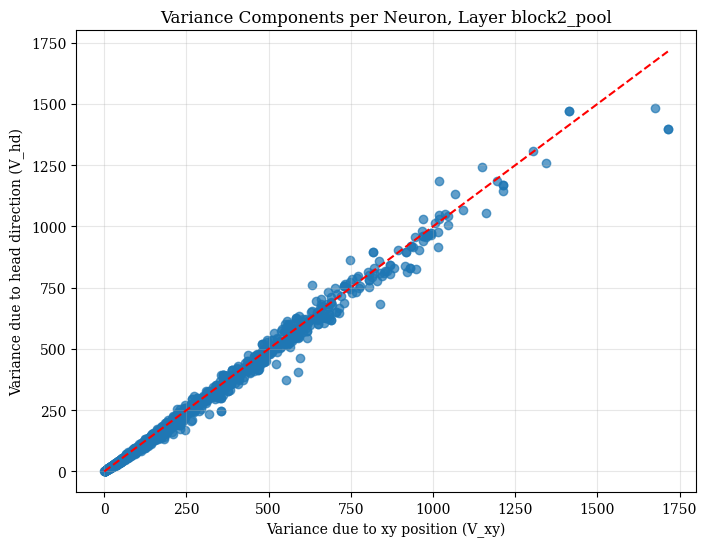

In [308]:
layer_idx = 0
layer = layers[layer_idx]

avg_xy = np.nanmean(layer_results[layer_idx]['xy'], axis=0)
avg_hd = np.nanmean(layer_results[layer_idx]['hd'], axis=0)

plt.figure(figsize=(8, 6))
plt.scatter(avg_xy, avg_hd, alpha=0.7)
plt.plot([0, max(avg_xy.max(), avg_hd.max())], 
         [0, max(avg_xy.max(), avg_hd.max())], 
         color='red', linestyle='--')
plt.title(f'Variance Components per Neuron, Layer {layer}')
plt.xlabel('Variance due to xy position (V_xy)')
plt.ylabel('Variance due to head direction (V_hd)')
#plt.xlim(0, 200)
#plt.ylim(0, 200)
plt.grid(alpha=0.3)

plt.savefig(f'variance_comp_per_neuron_{model_name}_{layer}.png')
plt.show()

In [24]:
n_rotations

17

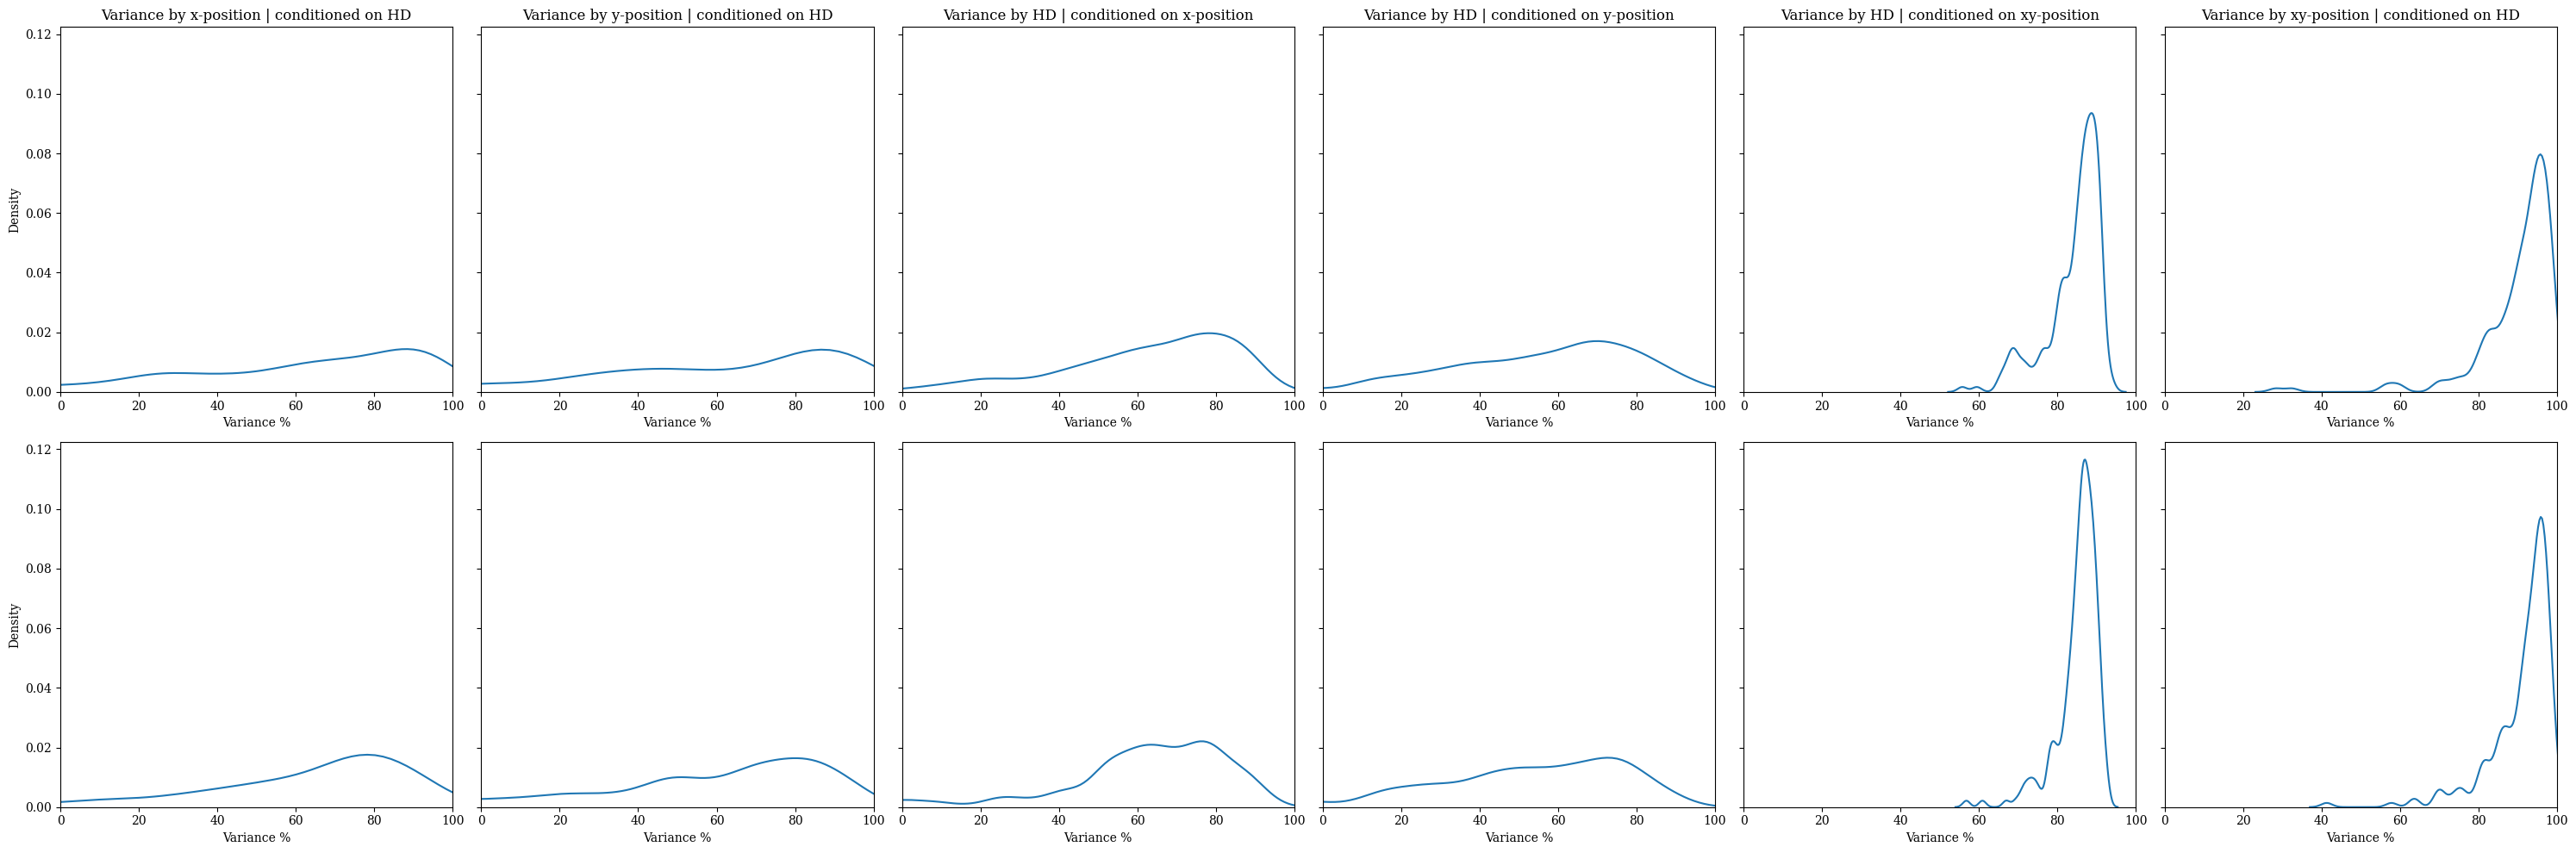

In [13]:
# Plotting
import seaborn as sns

fig, axes = plt.subplots(n_layers, 6, figsize=(30, 5 * n_layers), sharey=True)
titles = [
    'Variance by x-position | conditioned on HD',
    'Variance by y-position | conditioned on HD',
    'Variance by HD | conditioned on x-position',
    'Variance by HD | conditioned on y-position',
    'Variance by HD | conditioned on xy-position',
    'Variance by xy-position | conditioned on HD',
]

for layer_idx in range(n_layers):
    final_results = per_layer_final_results[layer_idx]
    # Average across trials
    for condition in final_results.keys():
        final_results[condition] = np.nanmean(final_results[condition], axis=0)

    for i, category in enumerate(final_results.keys()):
        ax = axes[layer_idx, i]
        sns.kdeplot(final_results[category], ax=ax, bw_adjust=0.5)
        if layer_idx == 0:
            ax.set_title(titles[i])
        if i == 0:
            ax.set_ylabel('Density')
        ax.set_xlabel('Variance %')
        ax.set_xlim(0, 100)

plt.tight_layout()
plt.savefig(f'variance_density_per_neuron_per_layer_{model_name}.png', dpi=300)
plt.show()

In [9]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(n_layers, 6, figsize=(30, 5 * n_layers), sharey=True)

# Define titles for each column
titles = [
    'Variance by x-position | conditioned on HD',
    'Variance by y-position | conditioned on HD',
    'Variance by HD | conditioned on x-position',
    'Variance by HD | conditioned on y-position',
    'Variance by xy-position | conditioned on HD',
    'Variance by HD | conditioned on xy-position'
]


for layer_idx in range(n_layers):
    # Get data for the current layer
    x_var_data = layer_x_var_results[layer_idx]
    y_var_data = layer_y_var_results[layer_idx]
    hd_x_var_data = layer_hd_x_results[layer_idx]
    hd_y_var_data = layer_hd_y_results[layer_idx]

    # Create bar plots for each metric
    for col_idx, data in enumerate([x_var_data, y_var_data, hd_x_var_data, hd_y_var_data, xy_hd_var_data, hd_xy_var_data]):
        ax = axes[layer_idx, col_idx]
        ax.bar(range(len(data)), data)
        if layer_idx == 0:  # Set titles only for the top row
            ax.set_title(titles[col_idx])
        if col_idx == 0:  # Label the rows with the layer name or index
            ax.set_ylabel(f'{layers[layer_idx]} Variance %')
        ax.set_xlabel('Neuron index')
        ax.set_ylim(0, 200)  # Fixed y-limit for consistency across layers

plt.tight_layout()

figpath = f'figs/{env}/2d/uniform/{model_name}/marginal_tuning'

# Save the figure
plt.savefig(f'{figpath}/variance_explained_per_layer.png', dpi=300)  # Adjust file name and dpi as needed
plt.close(fig)  # Close the figure to avoid displaying it in interactive environments


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd

fig, axes = plt.subplots(n_layers, 6, figsize=(30, 5 * n_layers), sharey=True)

# Define titles for each column
titles = [
    'Variance by x-position | conditioned on HD',
    'Variance by y-position | conditioned on HD',
    'Variance by HD | conditioned on x-position',
    'Variance by HD | conditioned on y-position',
    'Variance by xy-position | conditioned on HD',
    'Variance by HD | conditioned on xy-position'
]

kde_data = {'layer': [], 'condition': [], 'x_values': [], 'density_values': []}

for layer_idx in range(n_layers):
    # Get data for the current layer
    x_var_data = layer_x_var_results[layer_idx]
    y_var_data = layer_y_var_results[layer_idx]
    hd_x_var_data = layer_hd_x_results[layer_idx]
    hd_y_var_data = layer_hd_y_results[layer_idx]
    hd_xy_var_data = layer_hd_xy_results[layer_idx]
    xy_hd_var_data = layer_xy_hd_results[layer_idx]

    layer_pdfs = []

    # Create PDFs for each metric using seaborn's KDE plot
    for col_idx, data in enumerate([x_var_data, y_var_data, hd_x_var_data, hd_y_var_data, xy_hd_var_data, hd_xy_var_data]):
        print(data[0])
        ax = axes[layer_idx, col_idx]
        kde = sns.kdeplot(data, ax=ax, bw_adjust=0.5)
        #sns.kdeplot(data, ax=ax, fill=True, bw_adjust=0.5)
        if layer_idx == 0:
            ax.set_title(titles[col_idx])
        if col_idx == 0:
            ax.set_ylabel(f'{layers[layer_idx]} Density')
        ax.set_xlabel('Variance %')
        ax.set_xlim(0, 100) 

        x_values = kde.get_lines()[0].get_xdata()
        density_values = kde.get_lines()[0].get_ydata()

        #print(density_values[189])

        kde_data['layer'].append(layers[layer_idx])
        kde_data['condition'].append(titles[col_idx])
        kde_data['x_values'].append(x_values)
        kde_data['density_values'].append(density_values)

plt.tight_layout()

#figpath = f'figs/{env}/2d/uniform/{model_name}/marginal_tuning'
#plt.savefig(f'{figpath}/variance_density_per_layer.png', dpi=300)
#plt.close(fig)

model_kde_df = pd.DataFrame(kde_data)

model_kde_df.to_csv(f'results/{env}/2d/uniform/{model_name}/kde_distributions.csv', index=False)


## Gaussian models

### HD as constant

In [45]:
import numpy as np
from sklearn.metrics import r2_score
from scipy.optimize import minimize
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

# Func_tion for head direction
def f_const(bins):
    return np.ones(bins.shape)

# 2D Gaussian function
def gaussian_2d(x, y, mu_x, mu_y, sigma_x, sigma_y, rho, A):
    # Compute covariance matrix
    cov_matrix = np.array([
        [sigma_x**2, rho * sigma_x * sigma_y],
        [rho * sigma_x * sigma_y, sigma_y**2]
    ])
    cov_matrix += np.eye(2) * 1e-6
    # Check for singular covariance matrix
    try:
        inv_cov = np.linalg.inv(cov_matrix)
        det_cov = np.linalg.det(cov_matrix)
        if det_cov <= 0:  # Ensure determinant is positive
            raise ValueError("Covariance matrix is singular or non-positive definite.")
    except np.linalg.LinAlgError:
        inv_cov = np.eye(2)  # Default to identity matrix
        det_cov = 1.0

    x_grid, y_grid = np.meshgrid(x, y, indexing='ij') 
    diff = np.stack([x_grid - mu_x, y_grid - mu_y], axis=-1)
    
    exp_term = np.einsum('...i,ij,...j->...', diff, inv_cov, diff)
    exp_term = np.clip(exp_term, -100, 100)  # Clip to prevent overflow
    gaussian = A * np.exp(-0.5 * exp_term) / (2 * np.pi * np.sqrt(det_cov))
    #gaussian = A * np.exp(-0.5 * exp_term)
    #return gaussian
    return np.nan_to_num(gaussian)  # Replace NaNs with 0

# Model for place cell firing rates
def place_cell_model(x, y, hd, mu_x, mu_y, sigma_x, sigma_y, rho, A):
    f_xy = gaussian_2d(x, y, mu_x, mu_y, sigma_x, sigma_y, rho, A)
    f_hd_vals = f_const(hd)
    return f_xy[..., None] * f_hd_vals

def model_error(params, x, y, hd, firing_rate):
    mu_x, mu_y, sigma_x, sigma_y, rho, A = params
    predicted_rate = place_cell_model(x, y, hd, mu_x, mu_y, sigma_x, sigma_y, rho, A)
    error = np.nanmean((firing_rate - predicted_rate)**2)
    return error if np.isfinite(error) else np.inf

n_bins = 17
n_rotations = 17

n_neurons_to_sample = 100

x = np.arange(0, n_bins)
y = np.arange(0, n_bins)
theta = np.arange(0, n_rotations)

r2_per_layer = []
pred_ratemaps_per_layer = []
fitted_params_per_layer = []

for layer_idx, layer in enumerate(layers):
    print(layer)

    place_cells = layer_unit_indices[layer_idx][:n_neurons_to_sample]

    n_neurons = len(place_cells)

    r2_results = np.zeros(n_neurons)
    predicted_ratemaps = np.zeros((n_neurons, n_bins, n_bins, n_rotations))
    fitted_params = np.zeros((n_neurons, 6))

    for n, neuron_idx in enumerate(place_cells):
        heatmap = layer_reps[layer_idx][:, neuron_idx].reshape((n_bins, n_bins, n_rotations))
    
        initial_params = [np.mean(x), np.mean(y), np.std(x), np.std(y), 0, np.max(heatmap)]  # rho starts at 0
        
        try:
            bounds = [
                (0, n_bins),      # mu_x: within the range of x
                (0, n_bins),      # mu_y: within the range of y
                (1e-3, n_bins),   # sigma_x: strictly positive
                (1e-3, n_bins),   # sigma_y: strictly positive
                (-0.5, 0.5),     # rho: within [-1, 1] but avoid exactly ±1,
                (0, None)
            ]
    
            result = minimize(
                model_error,
                initial_params,
                args=(x, y, theta, heatmap),
                bounds=bounds
            )
        except ValueError as e:
            print(f"Neuron {n}: Optimization failed with error {e}")
            r2_results[n] = np.nan
            continue
    
        mu_x_opt, mu_y_opt, sigma_x_opt, sigma_y_opt, rho_opt, A_opt = result.x
        fitted_params[n] = result.x
    
        optimized_rate = place_cell_model(x, y, theta, mu_x_opt, mu_y_opt, sigma_x_opt, sigma_y_opt, rho_opt, A_opt)
        predicted_ratemaps[n] = optimized_rate

        if np.all(predicted_ratemaps[n] == 0.):
            print("all zero")
            print("heatmap fucked?", np.any(heatmap < 0))
        
        if not np.any(np.isnan(optimized_rate)):
            r_squared = r2_score(heatmap.flatten(), optimized_rate.flatten())
            r2_results[n] = r_squared if np.isfinite(r_squared) else np.nan
        else:
            print('nan')
            r2_results[n] = np.nan

    r2_per_layer.append(r2_results)
    pred_ratemaps_per_layer.append(predicted_ratemaps)
    fitted_params_per_layer.append(fitted_params)

    np.save(f'{model_name}_{layer}_r2_gaussian_results.npy', r2_results)


conv2_block3_out


### HD as Gaussian

In [50]:
import numpy as np
from sklearn.metrics import r2_score
from scipy.optimize import minimize
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

# 2D Gaussian function
def gaussian_2d(x, y, mu_x, mu_y, sigma_x, sigma_y, rho, A):
    cov_matrix = np.array([
        [sigma_x**2, rho * sigma_x * sigma_y],
        [rho * sigma_x * sigma_y, sigma_y**2]
    ])
    cov_matrix += np.eye(2) * 1e-6
    try:
        inv_cov = np.linalg.inv(cov_matrix)
        det_cov = np.linalg.det(cov_matrix)
        if det_cov <= 0:
            raise ValueError("Covariance matrix is singular or non-positive definite.")
    except np.linalg.LinAlgError:
        inv_cov = np.eye(2)
        det_cov = 1.0

    x_grid, y_grid = np.meshgrid(x, y, indexing='ij') 
    diff = np.stack([x_grid - mu_x, y_grid - mu_y], axis=-1)
    exp_term = np.einsum('...i,ij,...j->...', diff, inv_cov, diff)
    exp_term = np.clip(exp_term, -100, 100)
    gaussian = A * np.exp(-0.5 * exp_term) / (2 * np.pi * np.sqrt(det_cov))
    return np.nan_to_num(gaussian)

# Gaussian function for head direction
def gaussian_hd(bins, mu_hd, sigma_hd, A_hd):
    return A_hd * np.exp(-0.5 * ((bins - mu_hd) / sigma_hd) ** 2)

# Model for place cell firing rates
def place_cell_model(x, y, hd, mu_x, mu_y, sigma_x, sigma_y, rho, A_xy, mu_hd, sigma_hd, A_hd):
    f_xy = gaussian_2d(x, y, mu_x, mu_y, sigma_x, sigma_y, rho, A_xy)
    f_hd_vals = gaussian_hd(hd, mu_hd, sigma_hd, A_hd)
    return f_xy[..., None] * f_hd_vals

def model_error(params, x, y, hd, firing_rate):
    mu_x, mu_y, sigma_x, sigma_y, rho, A_xy, mu_hd, sigma_hd, A_hd = params
    predicted_rate = place_cell_model(x, y, hd, mu_x, mu_y, sigma_x, sigma_y, rho, A_xy, mu_hd, sigma_hd, A_hd)
    error = np.nanmean((firing_rate - predicted_rate) ** 2)
    return error if np.isfinite(error) else np.inf

n_bins = 17
n_rotations = 17

n_neurons_to_sample = 100

x = np.arange(0, n_bins)
y = np.arange(0, n_bins)
theta = np.arange(0, n_rotations)

r2_per_layer = []
pred_ratemaps_per_layer = []
fitted_params_per_layer = []

for layer_idx, layer in enumerate(layers):
    print(layer)

    place_cells = layer_unit_indices[layer_idx][:n_neurons_to_sample]

    n_neurons = len(place_cells)

    r2_results = np.zeros(n_neurons)
    predicted_ratemaps = np.zeros((n_neurons, n_bins, n_bins, n_rotations))
    fitted_params = np.zeros((n_neurons, 9))  # Updated to 9 parameters

    for n, neuron_idx in enumerate(place_cells):
        heatmap = layer_reps[layer_idx][:, neuron_idx].reshape((n_bins, n_bins, n_rotations))

        initial_params = [
            np.mean(x),          # mu_x
            np.mean(y),          # mu_y
            np.std(x),           # sigma_x
            np.std(y),           # sigma_y
            0,                   # rho
            np.max(heatmap),     # A_xy
            np.mean(theta),      # mu_hd
            np.std(theta),       # sigma_hd
            1.0                  # A_hd
        ]

        try:
            bounds = [
                (0, n_bins),              # mu_x
                (0, n_bins),              # mu_y
                (1e-3, n_bins),           # sigma_x
                (1e-3, n_bins),           # sigma_y
                (-0.5, 0.5),              # rho
                (0, None),                # A_xy
                (0, n_rotations),         # mu_hd
                (1e-3, n_rotations),      # sigma_hd
                (0, None)                 # A_hd
            ]

            result = minimize(
                model_error,
                initial_params,
                args=(x, y, theta, heatmap),
                bounds=bounds
            )
        except ValueError as e:
            print(f"Neuron {n}: Optimization failed with error {e}")
            r2_results[n] = np.nan
            continue

        mu_x_opt, mu_y_opt, sigma_x_opt, sigma_y_opt, rho_opt, A_xy_opt, mu_hd_opt, sigma_hd_opt, A_hd_opt = result.x
        fitted_params[n] = result.x

        optimized_rate = place_cell_model(x, y, theta, mu_x_opt, mu_y_opt, sigma_x_opt, sigma_y_opt, rho_opt, A_xy_opt, mu_hd_opt, sigma_hd_opt, A_hd_opt)
        predicted_ratemaps[n] = optimized_rate

        if np.all(predicted_ratemaps[n] == 0.):
            print("All zero predicted rates.")
            print("Any negative values in heatmap?", np.any(heatmap < 0))

        if not np.any(np.isnan(optimized_rate)):
            r_squared = r2_score(heatmap.flatten(), optimized_rate.flatten())
            r2_results[n] = r_squared if np.isfinite(r_squared) else np.nan
        else:
            print('NaN encountered in optimized rate.')
            r2_results[n] = np.nan

    r2_per_layer.append(r2_results)
    pred_ratemaps_per_layer.append(predicted_ratemaps)
    fitted_params_per_layer.append(fitted_params)

    np.save(f'{model_name}_{layer}_r2_gaussian_results.npy', r2_results)


avg_pool


### Plotting

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns  # Import seaborn for the KDE plot

bin_size = 200 // n_bins
for l, layer in enumerate(layers):
    pdf = PdfPages(f'{model_name}_{layer}_model_fits_gaussian_hd.pdf')
    
    # --- Add R² Distribution Plot on the First Page ---
    
    r2_results_clean = np.nan_to_num(r2_per_layer[l])
    
    # Create figure for R² distribution
    fig_r2 = plt.figure(figsize=(8, 6))
    sns.kdeplot(r2_results_clean, fill=True, bw_adjust=0.5)
    plt.title("Distribution of Model R² Across Neurons")
    plt.xlabel("R² Value")
    plt.ylabel("Density")
    plt.tight_layout()
    
    pdf.savefig(fig_r2)
    plt.close(fig_r2)
    
    # --- Loop Over Neurons and Generate Dual Plots ---

    place_cells = layer_unit_indices[l][:n_neurons_to_sample]
    n_neurons = len(place_cells)
    
    for n, neuron_idx in enumerate(place_cells):
        heatmap1 = layer_reps[l][:, neuron_idx].reshape((n_bins, n_bins, n_rotations))
        heatmap1 = np.sum(heatmap1, axis=2)
        
        heatmap2 = np.sum(predicted_ratemaps[n, :, :, :], axis=2)
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        
        im1 = axes[0].imshow(heatmap1, extent=[0, n_bins * bin_size, 0, n_bins * bin_size],
                             origin='lower', aspect='auto', cmap='hot')
        axes[0].set_title('Observed 2D Position Tuning Curve')
        axes[0].set_xlabel('X Position ')
        axes[0].set_ylabel('Y Position ')
        cbar1 = fig.colorbar(im1, ax=axes[0])
        cbar1.set_label('Firing Rate')
        
        im2 = axes[1].imshow(heatmap2, extent=[0, n_bins * bin_size, 0, n_bins * bin_size],
                             origin='lower', aspect='auto', cmap='hot')
        axes[1].set_title('Predicted 2D Position Tuning Curve')
        axes[1].set_xlabel('X Position ')
        axes[1].set_ylabel('Y Position ')
        cbar2 = fig.colorbar(im2, ax=axes[1])
        cbar2.set_label('Firing Rate')
        
        fig.suptitle(f'Neuron Index: {neuron_idx}', fontsize=16)
        
        plt.tight_layout()
        pdf.savefig(fig)
        plt.close(fig)
    
    pdf.close()

### Non-parametric

In [211]:
# first, smooth over the rate maps

def adjRateMaps(smoothMaps,maps,timeWindow):# do we even need to multiply by tau again
    adjustedMap= np.asarray([smoothMaps[:,:,k]*(np.max(maps[:,:,k]) / np.max(smoothMaps[:,:,k])) 
                    for k in range(len(maps[0,0,:]))]) 
    smagMap = np.zeros(np.shape(smoothMaps))
    for k in range(len(smoothMaps[0,0,:])): #bad dimensions Madge
        smagMap[:,:,k] = adjustedMap[k,:,:]
    return smagMap

n_bins = 17
n_rotations = 17

n_neurons_to_sample = 400

x = np.arange(0, n_bins)
y = np.arange(0, n_bins)
theta = np.arange(0, n_rotations)

smoothed_ratemaps_per_layer = []

sigma = 6
edgeBound = 5
tau = 0.120
env_len = 17
bin_count = 17

spatial_bins = np.linspace(0, env_len, bin_count)

# trying to mirror Dylan's code as much as possible here

for layer_idx, layer in enumerate(layers):
    print(layer)

    place_cells = layer_unit_indices[layer_idx][:n_neurons_to_sample]
    n_neurons = len(place_cells)

    stacked_heatmaps = np.zeros((n_bins, n_bins, n_neurons))
    
    for n, neuron_idx in enumerate(place_cells):
        heatmap = layer_reps[layer_idx][:, neuron_idx].reshape((n_bins, n_bins, n_rotations))
        stacked_heatmaps[:, :, n] = np.nanmean(heatmap, axis=2) 

    sigma = 2
    edgeBound = 5
    filterRange = spatial_bins - n_bins
    filterX, filterY = np.meshgrid(filterRange, filterRange)
    smoothRateMaps = np.zeros(np.shape(stacked_heatmaps))
        
    for i in range(len(spatial_bins)):
        for j in range(len(spatial_bins)):
            gaussFilter = (np.exp(-(((filterX - spatial_bins[j]) + bin_count) ** 2 + ((filterY - spatial_bins[i]) + bin_count) ** 2)
                                / (2 * sigma ** 2))) / (2 * np.pi * sigma ** 2)
            smoothRateMaps[i, j, :] = [np.sum(stacked_heatmaps[:, :, k]) for k in range(n_neurons)]
        
    #smoothRateMaps = adjRateMaps(smoothRateMaps, stacked_heatmaps, tau)

    smoothed_ratemaps_per_layer.append(smoothRateMaps)



avg_pool


avg_pool


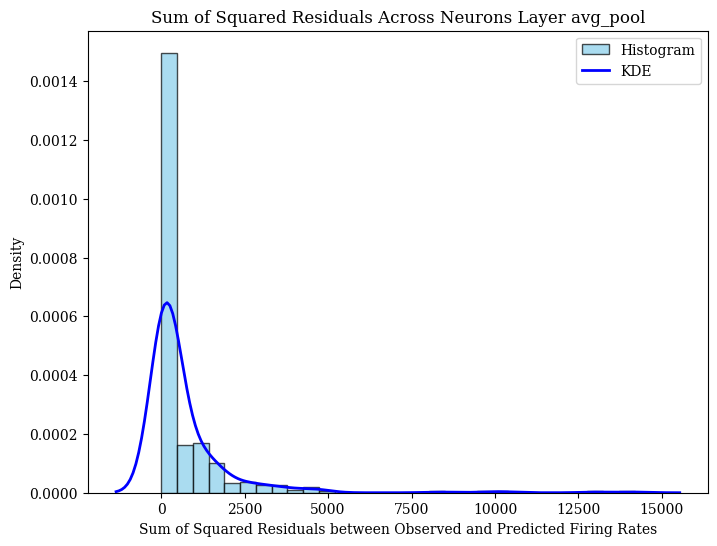

In [213]:
import numpy as np
from sklearn.metrics import r2_score
from scipy.stats import linregress
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

envLen = 17
n_bins = 17
n_rotations = 17
binWidth = envLen / n_bins

r2_results_per_layer = []
p_values_per_layer = []

for layer_idx, layer in enumerate(layers):
    print(layer)

    place_cells = layer_unit_indices[layer_idx][:n_neurons_to_sample]
    n_neurons = len(place_cells)

    r2_results = np.zeros(n_neurons)
    p_values = np.zeros(n_neurons)  # For HD dependence
    
    hd_angles = np.linspace(0, 360, n_rotations, endpoint=False)
    
    for j, neuron_idx in enumerate(place_cells):
        observed_rates = layer_reps[layer_idx][:, neuron_idx].reshape((n_bins, n_bins, n_rotations))
        observed_rates = np.nan_to_num(observed_rates)  # Replace NaNs with 0
    
        f1_xy = np.sum(observed_rates, axis=2) / n_rotations # Shape: (n_bins, n_bins)
        f1_xy = np.nan_to_num(f1_xy)
    
        f1_xy_expanded = np.repeat(f1_xy[:, :, np.newaxis], n_rotations, axis=2)  # Shape: (n_bins, n_bins, n_rotations)
    
        residuals = observed_rates - f1_xy_expanded  # Shape: (n_bins, n_bins, n_rotations)
    
        residuals_flat = residuals.flatten()
        valid_mask = ~np.isnan(residuals_flat)
    
        observed_flat = observed_rates.flatten()
        predicted_flat = f1_xy_expanded.flatten()
        valid_mask_r2 = ~np.isnan(observed_flat) & ~np.isnan(predicted_flat)
        if np.any(valid_mask_r2):
            #r_squared = r2_score(observed_flat[valid_mask_r2], predicted_flat[valid_mask_r2])
            r_squared = np.nansum((residuals)**2)
            r2_results[j] = r_squared
        else:
            r2_results[j] = np.nan

    r2_results_per_layer.append(r2_results)

r2_results = r2_results_per_layer[0]
n_neurons = layer_unit_indices[layer_idx][:n_neurons_to_sample]

# Plot R² values with KDE over histogram
plt.figure(figsize=(8, 6))
plt.hist(r2_results[~np.isnan(r2_results)], bins=30, color='skyblue', edgecolor='k', alpha=0.7, density=True, label='Histogram')
sns.kdeplot(r2_results[~np.isnan(r2_results)], color='blue', label='KDE', linewidth=2)
plt.xlabel(f'Sum of Squared Residuals between Observed and Predicted Firing Rates')
plt.ylabel('Density')
plt.title(f'Sum of Squared Residuals Across Neurons Layer {layers[0]}')
plt.legend()
plt.show()



# Pfeiffer data

In [66]:
import numpy as np

fold_seed = 111
hdBinCount=17

smoothRateMaps = np.load(f'/home/mag/Space/results/pfeiffer/smoothRateMaps_seed_{fold_seed}_hdBinCount_{hdBinCount}.npy') # smoothed xy map: n_bins, n_bins, n_neurons
rateMaps = np.load(f'/home/mag/Space/results/pfeiffer/rateMaps_seed_{fold_seed}_hdBinCount_{hdBinCount}.npy') # smoothed xy map: n_bins, n_bins, n_neurons
hdRateMap = np.load(f'/home/mag/Space/results/pfeiffer/hdRateMap_seed_{fold_seed}_hdBinCount_{hdBinCount}.npy') # firing rate per hd: n_bins, n_bins, n_rotations, n_neurons
hdOccupancyMap = np.load(f'/home/mag/Space/results/pfeiffer/hdOccupancyMap_seed_{fold_seed}_hdBinCount_{hdBinCount}.npy') # visit counts: n_bins, n_bins, n_rotations
hdRateMap_train = np.load(f'/home/mag/Space/results/pfeiffer/hdRateMap_seed_{fold_seed}_fold0_hdBinCount_{hdBinCount}.npy')
hdRateMap_test = np.load(f'/home/mag/Space/results/pfeiffer/hdRateMap_seed_{fold_seed}_fold1_hdBinCount_{hdBinCount}.npy')

print(hdRateMap_train.shape)

n_bins = hdRateMap.shape[0]
print(n_bins)
n_rotations = hdRateMap.shape[3]
n_neurons = hdRateMap.shape[2]

hdRateMap_train = np.transpose(hdRateMap_train, axes=[2, 0, 1, 3])
hdRateMap_test = np.transpose(hdRateMap_test, axes=[2, 0, 1, 3])

envLen = 200
binWidth = envLen/n_bins


(17, 17, 203, 17)
17


In [464]:
pfeiffer_path = '/home/mag/Space/results/pfeiffer'

sample = 'traj'

rateMaps = np.load(f'{pfeiffer_path}/rate_maps_nonselective_{sample}.npy') # smoothed xy map: n_bins, n_bins, n_neurons
hdRateMap = np.load(f'{pfeiffer_path}/hd_rate_maps_nonselective_{sample}.npy') # firing rate per hd: n_bins, n_bins, n_rotations, n_neurons
hdRateMap_train = np.load(f'{pfeiffer_path}/hd_rate_maps_train_nonselective_{sample}.npy')
hdRateMap_test = np.load(f'{pfeiffer_path}/hd_rate_maps_test_nonselective_{sample}.npy')

#nonselective_rateMaps = np.load(f'{pfeiffer_path}/rateMaps_nonselective.npy') # smoothed xy map: n_bins, n_bins, n_neurons
#nonselective_hdRateMap = np.load(f'/home/mag/Space/results/hdRateMaps_nonselective.npy') # firing rate per hd: n_bins, n_bins, n_rotations, n_neurons
#nonselective_hdRateMap_train = np.load(f'/home/mag/Space/results/hdRateMaps_train_nonselective.npy')
#nonselective_hdRateMap_test = np.load(f'/home/mag/Space/results/hdRateMaps_test_nonselective.npy')

n_neurons = rateMaps.shape[0]
n_bins = hdRateMap.shape[1]
n_rotations = hdRateMap.shape[3]

envLen = 200
binWidth = envLen/n_bins



In [450]:
hdRateMap_train.shape

(17, 17, 203, 17)

In [ ]:
totalsxy = np.zeros(hdRateMap_train.shape[2])
totalshd = np.zeros(hdRateMap_train.shape[2])

for i in range(hdRateMap_train.shape[2]):
    train_mean_xy = np.nanmean(hdRateMap_train[i].reshape(-1, n_rotations), axis=0)
    test_mean_xy = np.nanmean(hdRateMap_test[i].reshape(-1, n_rotations), axis=0)
    train_mean_hd = np.nanmean(hdRateMap_train[i].reshape(-1, n_rotations), axis=1)
    test_mean_hd = np.nanmean(hdRateMap_test[i].reshape(-1, n_rotations), axis=1)
    
    avg_diff_xy = np.nanmean(np.abs(train_mean_xy - test_mean_xy))
    avg_diff_hd = np.nanmean(np.abs(train_mean_hd - test_mean_hd))

    totalsxy[i] = avg_diff_xy
    totalshd[i] = avg_diff_hd
    
    print('average difference test/train means')
    print('xy', avg_diff_xy)
    print('hd', avg_diff_hd)
    
    avg_xy_train = np.nanmean(train_mean_xy)
    avg_xy_test = np.nanmean(test_mean_xy)
    avg_hd_train = np.nanmean(train_mean_hd)
    avg_hd_test = np.nanmean(test_mean_hd)
    
    print('average test/train means')
    
    print('xy train', avg_xy_train)
    print('xy test', avg_xy_test)
    print('hd train', avg_hd_train)
    print('hd test', avg_hd_test)
    print()
    
    avg_xy_train = np.nanvar(train_mean_xy)
    avg_xy_test = np.nanvar(test_mean_xy)
    avg_hd_train = np.nanvar(train_mean_hd)
    avg_hd_test = np.nanvar(test_mean_hd)
    
    #print('test/train vars')
    
    #print('xy train', avg_xy_train)
    #print('xy test', avg_xy_test)
    #print('hd train', avg_hd_train)
    #print('hd test', avg_hd_test)

print(np.nanmean(totalsxy), np.nanvar(totalsxy))
print(np.nanmean(totalshd), np.nanvar(totalshd))

/tmp/ipykernel_456186/1066346487.py:4: RuntimeWarning: Mean of empty slice
  train_mean_xy = np.nanmean(hdRateMap_train[i].reshape(-1, n_rotations), axis=0)
/tmp/ipykernel_456186/1066346487.py:5: RuntimeWarning: Mean of empty slice
  test_mean_xy = np.nanmean(hdRateMap_test[i].reshape(-1, n_rotations), axis=0)


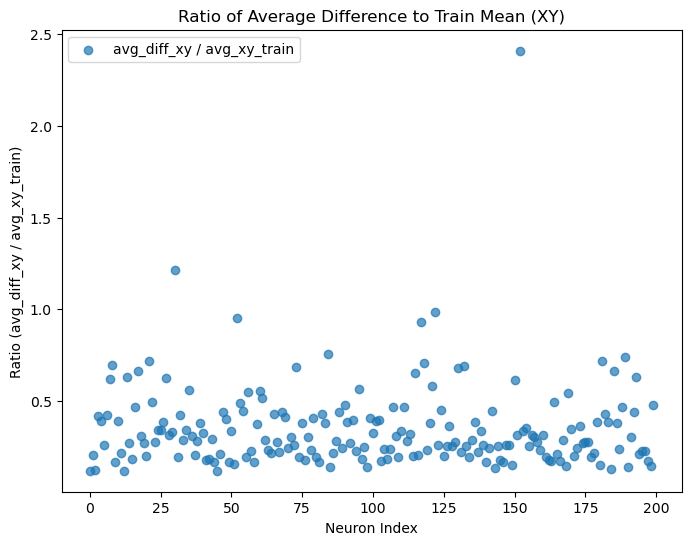

In [472]:
ratios_xy = np.zeros(hdRateMap_train.shape[0])

for i in range(hdRateMap_train.shape[0]):
    train_mean_xy = np.nanmean(hdRateMap_train[i].reshape(-1, n_rotations), axis=0)
    test_mean_xy = np.nanmean(hdRateMap_test[i].reshape(-1, n_rotations), axis=0)

    avg_diff_xy = np.nanmean(np.abs(train_mean_xy - test_mean_xy))
    avg_xy_train = np.nanmean(train_mean_xy)

    if avg_xy_train != 0:  # Avoid division by zero
        ratios_xy[i] = avg_diff_xy / avg_xy_train
    else:
        ratios_xy[i] = np.nan  # Mark as NaN if avg_xy_train is zero

# Scatter plot: Neuron Index vs. Ratio (avg_diff_xy / avg_xy_train)
plt.figure(figsize=(8, 6))
plt.scatter(range(hdRateMap_train.shape[0]), ratios_xy, alpha=0.7, label='avg_diff_xy / avg_xy_train')
plt.xlabel('Neuron Index')
plt.ylabel('Ratio (avg_diff_xy / avg_xy_train)')
plt.title('Ratio of Average Difference to Train Mean (XY)')
plt.legend()
plt.show()


/tmp/ipykernel_456186/3046992130.py:6: RuntimeWarning: Mean of empty slice
  train_mean_xy = np.nanmean(hdRateMap_train[i].reshape(-1, n_rotations), axis=1)
/tmp/ipykernel_456186/3046992130.py:7: RuntimeWarning: Mean of empty slice
  test_mean_xy = np.nanmean(hdRateMap_test[i].reshape(-1, n_rotations), axis=1)


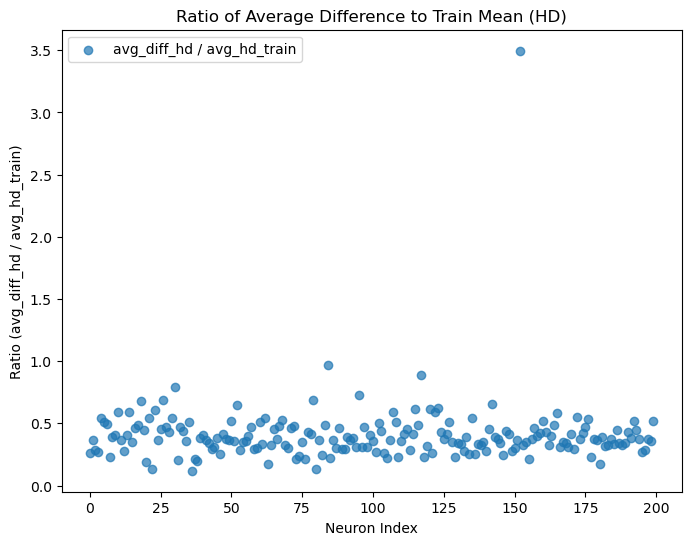

In [473]:
# THE HD CASE

ratios_xy = np.zeros(hdRateMap_train.shape[0])

for i in range(hdRateMap_train.shape[0]):
    train_mean_xy = np.nanmean(hdRateMap_train[i].reshape(-1, n_rotations), axis=1)
    test_mean_xy = np.nanmean(hdRateMap_test[i].reshape(-1, n_rotations), axis=1)

    avg_diff_xy = np.nanmean(np.abs(train_mean_xy - test_mean_xy))
    avg_xy_train = np.nanmean(train_mean_xy)

    if avg_xy_train != 0:  # Avoid division by zero
        ratios_xy[i] = avg_diff_xy / avg_xy_train
    else:
        ratios_xy[i] = np.nan  # Mark as NaN if avg_xy_train is zero

# Scatter plot: Neuron Index vs. Ratio (avg_diff_xy / avg_xy_train)
plt.figure(figsize=(8, 6))
plt.scatter(range(hdRateMap_train.shape[0]), ratios_xy, alpha=0.7, label='avg_diff_hd / avg_hd_train')
plt.xlabel('Neuron Index')
plt.ylabel('Ratio (avg_diff_hd / avg_hd_train)')
plt.title('Ratio of Average Difference to Train Mean (HD)')
plt.legend()
plt.show()

In [468]:
hdRateMap_train.shape

(200, 17, 17, 17)

/tmp/ipykernel_456186/3216555184.py:10: RuntimeWarning: Mean of empty slice
  train_mean_xy = np.nanmean(hdRateMap_train[i].reshape(-1, n_rotations), axis=0)
/tmp/ipykernel_456186/3216555184.py:11: RuntimeWarning: Mean of empty slice
  test_mean_xy = np.nanmean(hdRateMap_test[i].reshape(-1, n_rotations), axis=0)
/tmp/ipykernel_456186/3216555184.py:12: RuntimeWarning: Mean of empty slice
  train_mean_hd = np.nanmean(hdRateMap_train[i].reshape(-1, n_rotations), axis=1)
/tmp/ipykernel_456186/3216555184.py:13: RuntimeWarning: Mean of empty slice
  test_mean_hd = np.nanmean(hdRateMap_test[i].reshape(-1, n_rotations), axis=1)


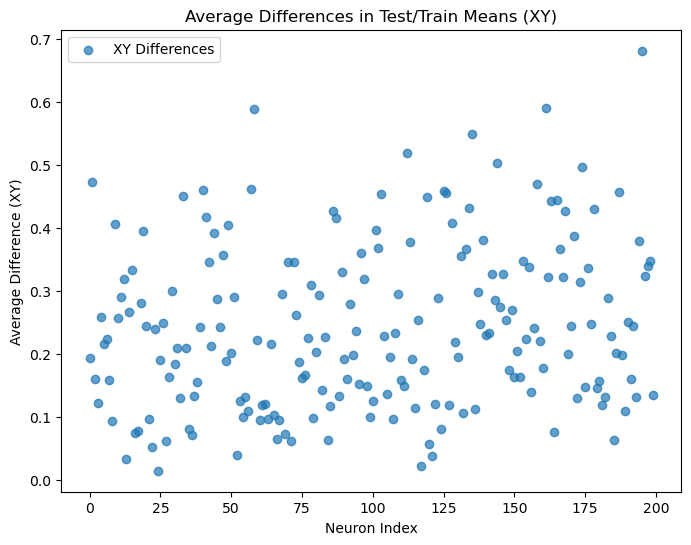

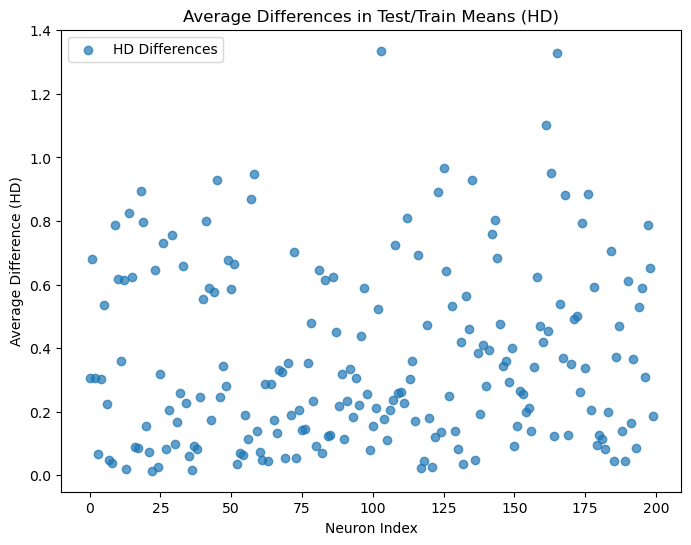

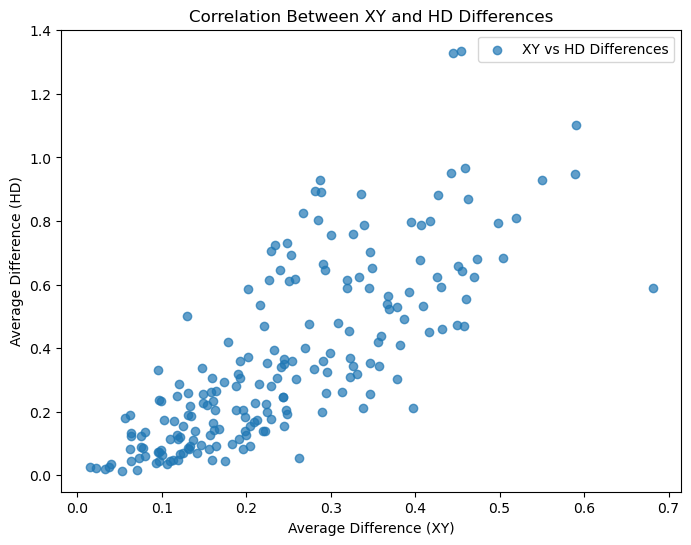

In [470]:
import numpy as np
import matplotlib.pyplot as plt

totalsxy = np.zeros(hdRateMap_train.shape[0])
totalshd = np.zeros(hdRateMap_train.shape[0])

n_rotations = hdRateMap_train.shape[2]

for i in range(hdRateMap_train.shape[0]):
    train_mean_xy = np.nanmean(hdRateMap_train[i].reshape(-1, n_rotations), axis=0)
    test_mean_xy = np.nanmean(hdRateMap_test[i].reshape(-1, n_rotations), axis=0)
    train_mean_hd = np.nanmean(hdRateMap_train[i].reshape(-1, n_rotations), axis=1)
    test_mean_hd = np.nanmean(hdRateMap_test[i].reshape(-1, n_rotations), axis=1)
    
    avg_diff_xy = np.nanmean(np.abs(train_mean_xy - test_mean_xy))
    avg_diff_hd = np.nanmean(np.abs(train_mean_hd - test_mean_hd))

    totalsxy[i] = avg_diff_xy
    totalshd[i] = avg_diff_hd

# Scatter plot: Neuron Index vs. Average Difference XY
plt.figure(figsize=(8, 6))
plt.scatter(range(hdRateMap_train.shape[0]), totalsxy, label='XY Differences', alpha=0.7)
plt.xlabel('Neuron Index')
plt.ylabel('Average Difference (XY)')
plt.title('Average Differences in Test/Train Means (XY)')
plt.legend()
plt.show()

# Scatter plot: Neuron Index vs. Average Difference HD
plt.figure(figsize=(8, 6))
plt.scatter(range(hdRateMap_train.shape[0]), totalshd, label='HD Differences', alpha=0.7)
plt.xlabel('Neuron Index')
plt.ylabel('Average Difference (HD)')
plt.title('Average Differences in Test/Train Means (HD)')
plt.legend()
plt.show()

# Scatter plot: XY Differences vs. HD Differences
plt.figure(figsize=(8, 6))
plt.scatter(totalsxy, totalshd, label='XY vs HD Differences', alpha=0.7)
plt.xlabel('Average Difference (XY)')
plt.ylabel('Average Difference (HD)')
plt.title('Correlation Between XY and HD Differences')
plt.legend()
plt.show()


## Quantifying variance

In [101]:

def quantify_variance(heatmap_test, heatmap_train, axis):
    '''
    Quantify the variance due to a certain variable in a cross-validated manner.
    Dim=[0, 1]
    heatmaps should be 2D
    Negative values indicate dominance of inherent variance over dimension-explained variance.
    '''
    
    test_mean = np.nanmean(heatmap_test, axis=axis)
    
    test_mean_expanded = test_mean[np.newaxis, :] if axis==0 else test_mean[:, np.newaxis]
    n_bins = heatmap_test.shape[axis]
    test_mean_expanded = np.repeat(test_mean_expanded, n_bins, axis=axis)

    train_mean = np.nanmean(heatmap_train, axis=axis)
    
    train_mean_expanded = train_mean[np.newaxis, :] if axis==0 else train_mean[:, np.newaxis]
    train_mean_expanded = np.repeat(train_mean_expanded, n_bins, axis=axis)

    test_total_mean = np.nanmean(heatmap_test)
    train_total_mean = np.nanmean(heatmap_train)

    estimator = 0.5 * (np.nansum((heatmap_test - test_mean_expanded)**2)
                 + np.nansum((heatmap_train - train_mean_expanded)**2)
                 - np.nansum((heatmap_test - heatmap_train)**2)
                 + n_bins * ((test_total_mean - train_total_mean)**2))

    return estimator
    

In [150]:
! ls results/dusz/Dataset_1

A1808-190807  A1813-190408  A5505-200831  A9701-210805


In [164]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

#use_hd_neurons = False

dataset = 'dusz'
#session = 'sub-A3716'
session = 'Dataset_6/A1110-180613'

hd_rate_map_test = np.load(f'results/{dataset}/{session}/dir_rate_map_fold0_n_dir_bins_17.npy')
hd_rate_map_train = np.load(f'results/{dataset}/{session}/dir_rate_map_fold1_n_dir_bins_17.npy')

#hd_neuron_idxs = np.load(f'results/{dataset}/{session}/hd_neuron_indexes.npy')

#if use_hd_neurons:
#    hd_rate_map_test = hd_rate_map_test[:, :, :, hd_neuron_idxs]
#    hd_rate_map_train = hd_rate_map_train[:, :, :, hd_neuron_idxs]
#else:
#    hd_rate_map_test = np.delete(hd_rate_map_test, hd_neuron_idxs, axis=3)
#    hd_rate_map_train = np.delete(hd_rate_map_train, hd_neuron_idxs, axis=3)

n_bins, _, n_rotations, n_neurons = hd_rate_map_test.shape

final_results = {
    'xy': np.zeros((n_neurons)),
    'dir': np.zeros((n_neurons)),
}
    
for idx in range(n_neurons):
    heatmap_test_flat = hd_rate_map_test[:, :, :, idx].reshape(-1, n_rotations)
    heatmap_train_flat = hd_rate_map_train[:, :, :, idx].reshape(-1, n_rotations)
    
    # Variance calculations
    var_xy = quantify_variance(heatmap_test_flat, heatmap_train_flat, axis=0)
    var_hd = quantify_variance(heatmap_test_flat, heatmap_train_flat, axis=1)
            
    final_results['dir'][idx] = var_hd
    final_results['xy'][idx] = var_xy

print(f"V_signal across {n_neurons} neurons in {session}:")
avg_var_xy = np.nanmean(final_results['xy'])
avg_var_hd = np.nanmean(final_results['dir'])
ratio = (avg_var_hd) / (avg_var_hd + avg_var_xy)
print(f"xy: {avg_var_xy:.6f}")
print(f"dir: {avg_var_hd:.6f}")
print(f"ratio dir / (xy + dir): {ratio:.2f}")
# hd_mystery dataset1 a1808
# looks like it really likes hd_mystery and not another_hd_mystery
# doesn't love mystery either but mostly fine

V_signal across 10 neurons in Dataset_6/A1110-180613:
xy: 228478.834331
dir: 162671.866277
ratio dir / (xy + dir): 0.42


/tmp/ipykernel_1871388/4022474470.py:9: RuntimeWarning: Mean of empty slice
  test_mean = np.nanmean(heatmap_test, axis=axis)
/tmp/ipykernel_1871388/4022474470.py:15: RuntimeWarning: Mean of empty slice
  train_mean = np.nanmean(heatmap_train, axis=axis)


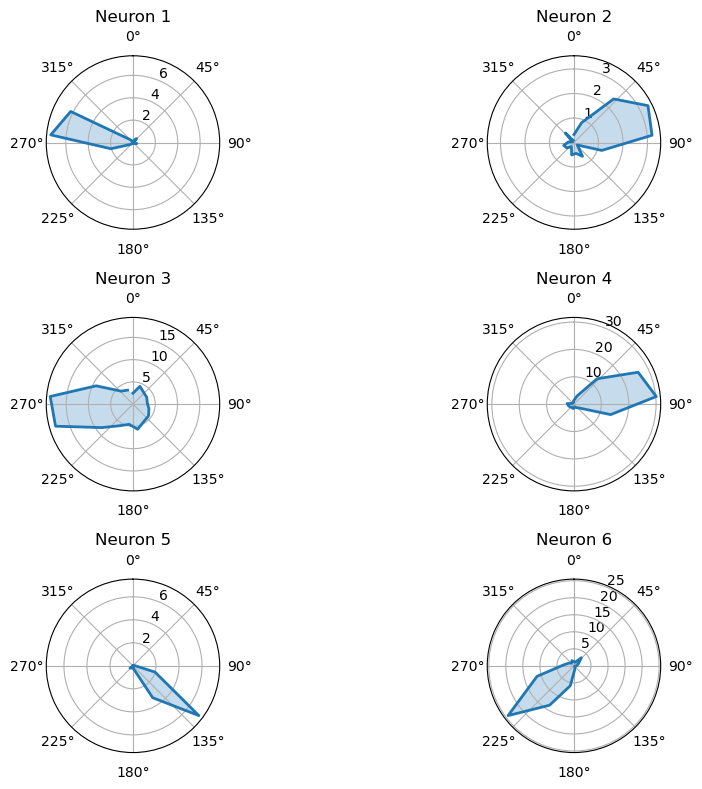

In [138]:
# plotting pwetty tuning curves

total_firing_rates = np.load(f'results/{dataset}/{session}/hd_rate_map_n_hd_bins_17.npy')
num_bins = total_firing_rates.shape[2]
mean_firing_rates = np.nanmean(total_firing_rates, axis=(0, 1))

# Angles for all bins
angles = np.linspace(0, 2*np.pi, num_bins, endpoint=False)

# Create a figure and subplots with polar projection
fig, axes = plt.subplots(3, 2, subplot_kw=dict(projection='polar'), figsize=(10, 8))
axes = axes.flatten()  # Flatten into a 1D list for easier iteration

for i, ax in enumerate(axes):
    ax.plot(angles, mean_firing_rates[:, i], linewidth=2, label=f'Dataset {i+1}')
    ax.fill(angles, mean_firing_rates[:, i], alpha=0.25)
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    ax.set_title(f"Neuron {i+1}")

# Optional layout adjustments and display
plt.tight_layout()
plt.show()


In [100]:
for i in range(len(final_results['xy'])):
    print(final_results['xy'][i], final_results['hd'][i])

2883752.365725673 2538520.1678284453
8685439.354551516 7199609.67415705
7357353.306096807 5788605.927170797
6076944.326377524 5020219.127678326
18422579.675830096 14131975.341928437
9149806.780065522 7536108.915221661
8595562.424898464 7227817.573868036
6587504.684102768 5334567.170367807
5207873.530975098 3407446.2049886067
20965860.77912921 14716008.578246042
19324094.955672964 14494605.224283822
16821956.896483667 12997284.220984854
16110189.317284659 11867236.381198924
8623266.516077055 6655791.200469597
5322460.326050609 3761966.8911124673
28541411.030407153 20038049.425095193
4458569.208205227 3522539.115263074
11007477.093356133 8714581.461124275
3007876.0744716423 2524927.4182107076
15212387.474191785 11736054.222726637
20135369.37563572 13777012.742913289
3383599.7798731863 2739357.8409540546
24568586.696926557 19228217.514687523
12969274.819691932 7415929.340906863
29650537.134350244 22066833.783714324
8256179.914867527 5978737.688524013
6068556.00604497 4622139.309172678


In [45]:
hd_rate_map_test.shape

(17, 17, 17, 203)

In [56]:
import numpy as np

hd_var = np.load(f'/home/mag/Space/results/pfeiffer/hd_variances.npy')
xy_var = np.load(f'/home/mag/Space/results/pfeiffer/xy_variances.npy')


In [59]:
xy_var[:, 2]

array([300.21305963, 247.96128856, 246.60064224, 274.93364375,
       311.29861185, 276.16654231, 261.51056311, 273.99272837,
       282.74442171, 283.09919506, 267.72332309, 257.11581975,
       214.31978413, 193.70585427, 260.59042243, 249.08262893,
       279.40214944, 264.13190591, 302.17567538, 279.15216792,
       247.35510801, 293.88345681, 272.9336639 , 277.14761326,
       247.95117753, 253.38572007, 265.32534785, 276.6018132 ,
       270.66966149, 277.99710083, 273.42054566, 278.42572549,
       249.56873486, 276.700571  , 261.21569538, 250.18884356,
       221.15838504, 221.74054256, 278.04571969, 238.10321627,
       288.12218568, 299.69185726, 281.94210436, 289.33185829,
       257.69166677, 267.23407444, 258.93988478, 283.060377  ,
       226.71891434, 258.49596855, 241.27574885, 284.53790374,
       298.41746586, 246.7032394 , 284.56627042, 295.36506242,
       290.6114204 , 306.45853045, 278.08365928, 272.86883928,
       269.62543419, 256.72730653, 259.24440097, 259.51

In [64]:
print(f"Average V_signal across neurons & splits:")
avg_var_xy = np.nanmean(xy_var)
avg_var_hd = np.nanmean(hd_var)
print(f"xy: {avg_var_xy:.6f}")
print(f"hd: {avg_var_hd:.6f}")

Average V_signal across neurons & splits:
xy: 390.098550
hd: -0.861419


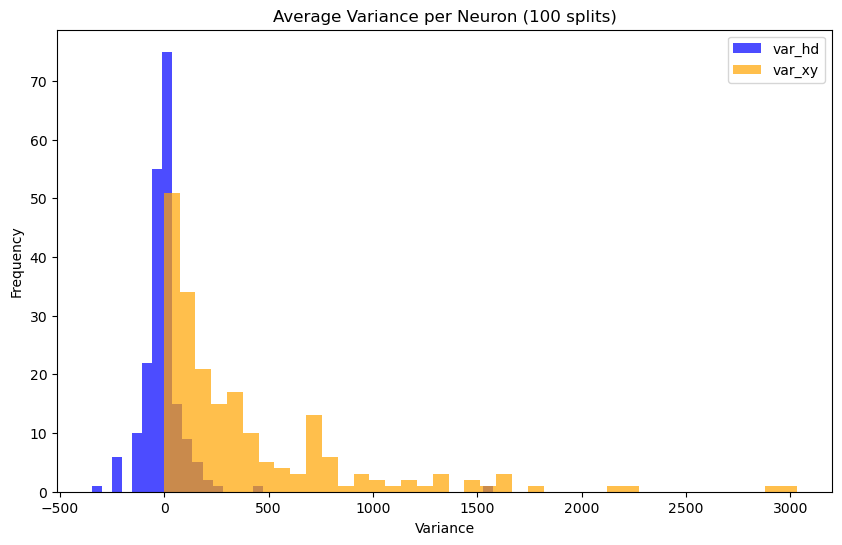

In [62]:
# all neurons all splits

import matplotlib.pyplot as plt

# Plot both histograms on the same figure
plt.figure(figsize=(10, 6))
plt.hist(np.nanmean(hd_var, axis=0), bins=40, alpha=0.7, color='blue', label='var_hd')
plt.hist(np.nanmean(xy_var, axis=0), bins=40, alpha=0.7, color='orange', label='var_xy')
#plt.xlim(0, 1)

splits = hd_var.shape[0]

# Add title and labels
plt.title(f"Average Variance per Neuron ({splits} splits)")
plt.xlabel("Variance")
plt.ylabel("Frequency")

# Add legend
plt.legend()

# Display the plot
plt.savefig('avg_var_neuron_new.png', dpi=200)
plt.show()


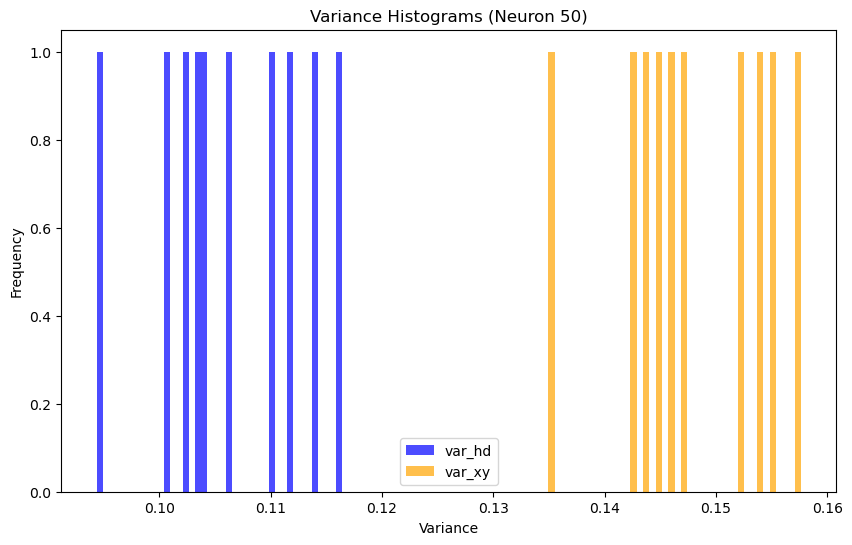

In [26]:
import matplotlib.pyplot as plt

# Allow user to pick a neuron index to display histogram of variances
neuron_index = 50

# Plot both histograms on the same figure
plt.figure(figsize=(10, 6))
plt.hist(hd_var[:, neuron_index], bins=40, alpha=0.7, color='blue', label='var_hd')
plt.hist(xy_var[:, neuron_index], bins=40, alpha=0.7, color='orange', label='var_xy')

# Add title and labels
plt.title(f"Variance Histograms (Neuron {neuron_index})")
plt.xlabel("Variance")
plt.ylabel("Frequency")

# Add legend
plt.legend()

# Display the plot
plt.show()


In [187]:
avg_xy

array([ 3554.67085237, 26136.19799689, 12751.35514091, 38401.52371014,
        7239.87736619])

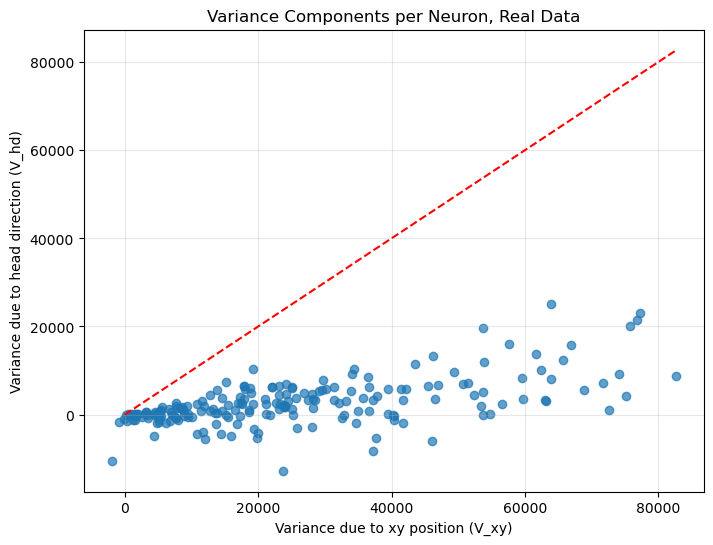

In [436]:
avg_xy = final_results['xy']#np.nanmean(final_results['xy'], axis=0)
avg_hd = final_results['hd']#np.nanmean(final_results['hd'], axis=0)

plt.figure(figsize=(8, 6))
plt.scatter(avg_xy, avg_hd, alpha=0.7)
plt.plot([0, max(avg_xy.max(), avg_hd.max())], 
         [0, max(avg_xy.max(), avg_hd.max())], 
         color='red', linestyle='--')
plt.title('Variance Components per Neuron, Real Data')
plt.xlabel('Variance due to xy position (V_xy)')
plt.ylabel('Variance due to head direction (V_hd)')
#plt.xlim(0, 3000)
#plt.ylim(0, 3000)
plt.grid(alpha=0.3)

plt.savefig('variance_comp_per_neuron_pfeiffer_full.png')
plt.show()


In [ ]:
# here I'm just checking if the means are the same in test and train sets 




In [277]:
def _compute_single_heatmap_directional_scores(activation_maps):
    """
    Args:
        `activation_maps` correspond to the un-summed activation maps
        for a single unit across rotations \in (n_locations, n_rotations)

    - num of angular bins in Banino here becomes `n_rotations`.
    - based on Banino eq, we need to convert each n_rotations to 
        `alpha_i` which is angle.
    - the intensity `beta_i` of an angle is the average activation 
        across all locations for that angle.
    """
    activation_maps = (activation_maps - np.min(activation_maps)) / (np.max(activation_maps) - np.min(activation_maps))
    
    num_bins = activation_maps.shape[1]
    alphas = np.linspace(0, 2*np.pi, num=n_rotations, endpoint=False)
    betas = np.mean(activation_maps, axis=0) # mean direction for this spatial bin

    polar_plot_coords = [] # (n_rotations, 2)
    per_rotation_vector_length = []
    for alpha_i, beta_i in zip(alphas, betas):
        polar_plot_coords.append(
            [beta_i*np.cos(alpha_i), beta_i*np.sin(alpha_i)]
        )
        per_rotation_vector_length.append(
            np.linalg.norm([beta_i*np.cos(alpha_i), beta_i*np.sin(alpha_i)])
        )
    
    r_normed_by_beta = np.sum(
        np.array(polar_plot_coords), axis=0) / np.sum(betas)

    mean_vector_length = np.linalg.norm(r_normed_by_beta)
    return mean_vector_length, per_rotation_vector_length
    

In [246]:
hd_ratios[sorted_ratio_idx][::-1][:20]

array([1.04948259, 0.65556671, 0.64543869, 0.60074972, 0.5621208 ,
       0.49216195, 0.46964   , 0.4217815 , 0.40625031, 0.40492497,
       0.40005325, 0.39921637, 0.3984599 , 0.39338742, 0.39275816,
       0.3862228 , 0.38415896, 0.38304003, 0.38281455, 0.38262416])

In [280]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.backends.backend_pdf import PdfPages

hd_ratios = avg_hd / avg_xy
sorted_ratio_idx = np.argsort(hd_ratios)[::-1]

n_to_plot = 10

nbins = 200
bin_size = envLen // nbins

theta = np.linspace(0, 2 * np.pi, n_rotations - 1, endpoint=False)

# Open a PDF file to save the figures
with PdfPages('pfeiffer_hd_tuned_neurons.pdf') as pdf:
    for neuron_idx in sorted_ratio_idx[:n_to_plot]:
        # Calculate data for this neuron
        firing_rate_total = np.nan_to_num(hdRateMap[:, :, neuron_idx, :])
        summed_firing_rate_total = np.nan_to_num(np.nanmean(hdRateMap[:, :, neuron_idx, :], axis=2))

        firing_rate_test = np.nan_to_num(hdRateMap_test[:, :, neuron_idx, :])
        summed_firing_rate_test = np.nan_to_num(np.nanmean(hdRateMap_test[:, :, neuron_idx, :], axis=2))

        firing_rate_train = np.nan_to_num(hdRateMap_train[:, :, neuron_idx, :])
        summed_firing_rate_train = np.nan_to_num(np.nanmean(hdRateMap_train[:, :, neuron_idx, :], axis=2))

        smoothed_firing_rate = smoothRateMaps[:, :, neuron_idx]

        mean_vector_length_test, per_rotation_vector_length_test = _compute_single_heatmap_directional_scores(
            firing_rate_test.reshape(-1, n_rotations))
        mean_vector_length_train, per_rotation_vector_length_train = _compute_single_heatmap_directional_scores(
            firing_rate_train.reshape(-1, n_rotations))
        mean_vector_length_total, per_rotation_vector_length_total = _compute_single_heatmap_directional_scores(
            firing_rate_total.reshape(-1, n_rotations))

        per_rotation_vector_length_test = per_rotation_vector_length_test[:-1]
        per_rotation_vector_length_train = per_rotation_vector_length_train[:-1]
        per_rotation_vector_length_total = per_rotation_vector_length_total[:-1]

        # Create the figure
        fig = plt.figure(figsize=(12, 19))
        gs = GridSpec(4, 2, figure=fig)

        # Total Heatmap
        ax1 = fig.add_subplot(gs[0, 0])
        im1 = ax1.imshow(summed_firing_rate_total, extent=[0, nbins * bin_size, 0, nbins * bin_size],
                         origin='lower', aspect='auto', cmap='hot')
        plt.colorbar(im1, ax=ax1, label='Firing Rate')
        ax1.set_xlabel('X Position')
        ax1.set_ylabel('Y Position')
        ax1.set_title('Total - 2D Position Tuning Curve')

        # Total Polar Plot
        ax2 = fig.add_subplot(gs[0, 1], projection='polar')
        x = theta.tolist() + [theta[0]]
        y = per_rotation_vector_length_total + [per_rotation_vector_length_total[0]]
        ax2.plot(x, y)
        ax2.set_theta_zero_location("N")
        ax2.set_theta_direction(-1)
        ax2.set_thetagrids([0, 90, 180, 270], labels=['0', '90', '180', '270'])
        ax2.set_title('Total - Head Direction')

        # Train Heatmap
        ax3 = fig.add_subplot(gs[1, 0])
        im2 = ax3.imshow(summed_firing_rate_train, extent=[0, nbins * bin_size, 0, nbins * bin_size],
                         origin='lower', aspect='auto', cmap='hot')
        plt.colorbar(im2, ax=ax3, label='Firing Rate')
        ax3.set_xlabel('X Position')
        ax3.set_ylabel('Y Position')
        ax3.set_title('Train - Rate Map')

        # Train Polar Plot
        ax4 = fig.add_subplot(gs[1, 1], projection='polar')
        x = theta.tolist() + [theta[0]]
        y = per_rotation_vector_length_train + [per_rotation_vector_length_train[0]]
        ax4.plot(x, y)
        ax4.set_theta_zero_location("N")
        ax4.set_theta_direction(-1)
        ax4.set_thetagrids([0, 90, 180, 270], labels=['0', '90', '180', '270'])
        ax4.set_title('Train - Head Direction')

        # Test Heatmap
        ax5 = fig.add_subplot(gs[2, 0])
        im3 = ax5.imshow(summed_firing_rate_test, extent=[0, nbins * bin_size, 0, nbins * bin_size],
                         origin='lower', aspect='auto', cmap='hot')
        plt.colorbar(im3, ax=ax5, label='Firing Rate')
        ax5.set_xlabel('X Position')
        ax5.set_ylabel('Y Position')
        ax5.set_title('Test - Rate Map')

        # Test Polar Plot
        ax6 = fig.add_subplot(gs[2, 1], projection='polar')
        x = theta.tolist() + [theta[0]]
        y = per_rotation_vector_length_test + [per_rotation_vector_length_test[0]]
        ax6.plot(x, y)
        ax6.set_theta_zero_location("N")
        ax6.set_theta_direction(-1)
        ax6.set_thetagrids([0, 90, 180, 270], labels=['0', '90', '180', '270'])
        ax6.set_title('Test - Head Direction')

        # Smooth Rate Map Total
        ax7 = fig.add_subplot(gs[3, 0])
        im4 = ax7.imshow(smoothed_firing_rate, extent=[0, nbins * bin_size, 0, nbins * bin_size],
                         origin='lower', aspect='auto', cmap='hot')
        plt.colorbar(im4, ax=ax7, label='Firing Rate')
        ax7.set_xlabel('X Position')
        ax7.set_ylabel('Y Position')
        ax7.set_title('Smooth Rate Map')

        # Add a super title with padding
        fig.suptitle(f'Neuron {neuron_idx}  |  v_hd / v_xy = {hd_ratios[neuron_idx]:.3f}', fontsize=18, y=0.99)

        plt.tight_layout()
        pdf.savefig(fig)  # Save the current figure to the PDF
        plt.close(fig)  # Close the figure to free up memory


/tmp/ipykernel_3627366/1380106410.py:20: RuntimeWarning: Mean of empty slice
  summed_firing_rate_total = np.nan_to_num(np.nanmean(hdRateMap[:, :, neuron_idx, :], axis=2))
/tmp/ipykernel_3627366/1380106410.py:23: RuntimeWarning: Mean of empty slice
  summed_firing_rate_test = np.nan_to_num(np.nanmean(hdRateMap_test[:, :, neuron_idx, :], axis=2))
/tmp/ipykernel_3627366/1380106410.py:26: RuntimeWarning: Mean of empty slice
  summed_firing_rate_train = np.nan_to_num(np.nanmean(hdRateMap_train[:, :, neuron_idx, :], axis=2))
/tmp/ipykernel_3627366/1380106410.py:20: RuntimeWarning: Mean of empty slice
  summed_firing_rate_total = np.nan_to_num(np.nanmean(hdRateMap[:, :, neuron_idx, :], axis=2))
/tmp/ipykernel_3627366/1380106410.py:23: RuntimeWarning: Mean of empty slice
  summed_firing_rate_test = np.nan_to_num(np.nanmean(hdRateMap_test[:, :, neuron_idx, :], axis=2))
/tmp/ipykernel_3627366/1380106410.py:26: RuntimeWarning: Mean of empty slice
  summed_firing_rate_train = np.nan_to_num(np.nan

In [235]:
per_rotation_vector_length_train[11]

0.0

In [134]:
firing_rate_total.shape

()

In [38]:
theta.shape

(16,)

In [55]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# hdRateMap contains average firing rate per x,y,hd bin and hdRateMap_train and _test contain
# the same but visits for each bin are split randomly between the two
# I want to understand the variance due to conditioning on a variable and I want to isolate
# that variance from the inherent variance of repeats to the same bin
# the idea being v_original - variance(firing rate per bin - mean firing rate conditioned on a variable)

n_neurons = hdRateMap.shape[2]
n_trials = 1

hdRateMap_normalized = hdRateMap #np.zeros(hdRateMap.shape) # n_bins, n_bins, n_neurons, n_rotations
hdRateMap_train_normalized = hdRateMap_train #np.zeros(hdRateMap_train.shape) # n_bins, n_bins, n_neurons, n_rotations
hdRateMap_test_normalized = hdRateMap_test #np.zeros(hdRateMap_test.shape) # n_bins, n_bins, n_neurons, n_rotations

# Initialize the final results dictionary
final_results = {
    'x_hd': np.zeros((n_neurons)),
    'y_hd': np.zeros((n_neurons)),
    'hd_x': np.zeros((n_neurons)),
    'hd_y': np.zeros((n_neurons)),
    'hd_xy': np.zeros((n_neurons)),
    'xy_hd': np.zeros((n_neurons)),
}

train_means = {
    'x_hd': np.zeros((n_neurons, n_rotations)),
    'y_hd': np.zeros((n_neurons, n_rotations)),
    'hd_x': np.zeros((n_neurons, n_bins)),
    'hd_y': np.zeros((n_neurons, n_bins)),
    'hd_xy': np.zeros((n_neurons, n_bins*n_bins)),
    'xy_hd': np.zeros((n_neurons, n_rotations)),
}

variances = np.zeros((n_neurons))

x_marginals_test = []
y_marginals_test = []

for idx in tqdm(range(n_neurons), desc="Building models"):
    # Train means
    heatmap = hdRateMap_train_normalized[:, :, idx, :]

    x_marginal = np.nanmean(heatmap, axis=0)
    y_marginal = np.nanmean(heatmap, axis=1)

    train_means['hd_x'][idx] = np.nanmean(x_marginal, axis=1)
    train_means['hd_y'][idx] = np.nanmean(y_marginal, axis=1)
    train_means['x_hd'][idx] = np.nanmean(x_marginal, axis=0) 
    train_means['y_hd'][idx] = np.nanmean(y_marginal, axis=0)
    
    heatmap_flat = heatmap.reshape(-1, n_rotations)
    train_means['xy_hd'][idx] = np.nanmean(heatmap_flat, axis=0) # n_rotations
    train_means['hd_xy'][idx] = np.nanmean(heatmap_flat, axis=1) # n_bins

    # Test marginals 
    heatmap = hdRateMap_test_normalized[:, :, idx, :]
    x_marginal = np.nansum(heatmap, axis=0) / n_bins
    y_marginal = np.nansum(heatmap, axis=1) / n_bins

    x_marginals_test.append(x_marginal)
    y_marginals_test.append(y_marginal)

    # Test variances
    variances[idx] = np.nanvar(hdRateMap_normalized[:, :, idx, :])

for idx in tqdm(range(n_neurons), desc="Calculating V_signal"):
    for category in train_means.keys():
        # Select the correct variables for the calculation and expand the category means so we can vectorize
        if category == 'x_hd' or category == 'y_hd':
            actual_values_test = x_marginals_test[idx] if category == 'x_hd' else y_marginals_test[idx]
            category_means_expanded_train = np.tile(train_means[category][idx], (n_bins, 1))
        elif category == 'hd_x' or category == 'hd_y':
            actual_values_test = x_marginals_test[idx] if category == 'hd_x' else y_marginals_test[idx] 
            category_means_expanded_train = train_means[category][idx][:, np.newaxis]
            category_means_expanded_train = np.repeat(category_means_expanded_train, n_rotations, axis=1)
        elif category == 'hd_xy':
            actual_values_test = hdRateMap_test_normalized[:, :, idx, :].reshape(-1, n_rotations)
            category_means_expanded_train = train_means[category][idx][:, np.newaxis] 
            category_means_expanded_train = np.repeat(category_means_expanded_train, n_rotations, axis=1) 
        elif category == 'xy_hd':
            actual_values_test = hdRateMap_test_normalized[:, :, idx, :].reshape(-1, n_rotations)
            category_means_expanded_train = train_means[category][idx][np.newaxis, :]
            category_means_expanded_train = np.repeat(category_means_expanded_train, n_bins * n_bins, axis=0) 
                
        else:
            continue

        residuals = actual_values_test - category_means_expanded_train
        v = np.nanvar(actual_values_test)
        #v_signal = ((variances[idx] - np.nanmean(residuals**2)) / variances[idx]) * 100
        v_signal = ((v - np.nanmean(residuals**2)) / variances[idx]) * 100
        
        final_results[category][idx] = v_signal


print("V_signal across neurons:")
for category in final_results.keys():
    avg_var = np.nanmean(final_results[category])
    print(f"{category}: {avg_var:.2f}%")

# okay so.
# I've tried the 


Calculating V_signal: 100%|█████████████████████████████████████████████████████████████████| 203/203 [00:00<00:00, 1541.91it/s]

V_signal across neurons:
x_hd: -4.47%
y_hd: -4.26%
hd_x: -4.09%
hd_y: -3.20%
hd_xy: 3.13%
xy_hd: -1.27%


In [194]:
# ok trying this a different way

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# I've split up my spike trains for a population of neurons into two folds, train and test
# The covariance between these two populations is a good measure of the signal variance for a stimulus
# here the stimuli we want to measure are x conditioned on hd, hd conditioned on xy, etc

n_neurons = hdRateMap.shape[2]
n_trials = 1

epsilon = 1e-8
hdRateMap_normalized = np.zeros(hdRateMap.shape) # n_bins, n_bins, n_neurons, n_rotations
hdRateMap_train_normalized = np.zeros(hdRateMap_train.shape) # n_bins, n_bins, n_neurons, n_rotations
hdRateMap_test_normalized = np.zeros(hdRateMap_test.shape) # n_bins, n_bins, n_neurons, n_rotations

for i in range(n_neurons):
    hdRateMap_normalized[:, :, i, :] = hdRateMap[:, :, i, :] / (hdOccupancyMap + epsilon)
    hdRateMap_train_normalized[:, :, i, :] = hdRateMap_train[:, :, i, :] / (hdOccupancyMap_train + epsilon)
    hdRateMap_test_normalized[:, :, i, :] = hdRateMap_test[:, :, i, :] / (hdOccupancyMap_test + epsilon)

# Initialize the final results dictionary
final_results = {
    'x_var': np.zeros((n_trials, n_neurons)),
    'y_var': np.zeros((n_trials, n_neurons)),
    'hd_x': np.zeros((n_trials, n_neurons)),
    'hd_y': np.zeros((n_trials, n_neurons)),
    'hd_xy': np.zeros((n_trials, n_neurons)),
    'xy_hd': np.zeros((n_trials, n_neurons)),
}

for trial in range(n_trials):
    # Calculate means for each dimension we care about
    test_means = {
        'x_var': np.zeros((n_neurons, n_rotations)),
        'y_var': np.zeros((n_neurons, n_rotations)),
        'hd_x': np.zeros((n_neurons, n_bins)),
        'hd_y': np.zeros((n_neurons, n_bins)),
        'hd_xy': np.zeros((n_neurons, n_rotations)),
        'xy_hd': np.zeros((n_neurons, n_rotations)),
    }

    train_means = {
        'x_var': np.zeros((n_neurons, n_rotations)),
        'y_var': np.zeros((n_neurons, n_rotations)),
        'hd_x': np.zeros((n_neurons, n_bins)),
        'hd_y': np.zeros((n_neurons, n_bins)),
        'hd_xy': np.zeros((n_neurons, n_rotations)),
        'xy_hd': np.zeros((n_neurons, n_rotations)),
    }

    x_marginals_train = []
    y_marginals_train = []
    x_marginals_test = []
    y_marginals_test = []

    for idx in tqdm(range(n_neurons), desc="Building models"):
        # Train means
        heatmap = hdRateMap_train_normalized[:, :, idx, :]
        x_marginal = np.sum(heatmap, axis=0)
        y_marginal = np.sum(heatmap, axis=1)

        x_marginals_train.append(x_marginal)
        y_marginals_train.append(y_marginal)

        train_means['hd_x'][idx] = np.nanmean(x_marginal, axis=1) # n_bins, the mean head direction firing rate per x bin
        train_means['hd_y'][idx] = np.nanmean(y_marginal, axis=1)
        train_means['x_var'][idx] = np.nanmean(x_marginal, axis=0) # n_rotations
        train_means['y_var'][idx] = np.nanmean(y_marginal, axis=0)
        train_means['hd_xy'][idx] = np.nanmean(heatmap, axis=(0, 1))#2)   # n_bins x n_bins
        #train_means['xy_hd'][idx] = np.nanmean(heatmap, axis=2)#(0, 1)) # n_rotations
        heatmap_flat = heatmap.reshape(-1, n_rotations)
        train_means['xy_hd'][idx] = np.nanmean(heatmap_flat, axis=0)

        # Test means 
        heatmap = hdRateMap_test_normalized[:, :, idx, :]
        x_marginal = np.sum(heatmap, axis=0)
        y_marginal = np.sum(heatmap, axis=1)

        x_marginals_test.append(x_marginal)
        y_marginals_test.append(y_marginal)

        test_means['hd_x'][idx] = np.nanmean(x_marginal, axis=1) # n_bins, the mean head direction firing rate per x bin
        test_means['hd_y'][idx] = np.nanmean(y_marginal, axis=1)
        test_means['x_var'][idx] = np.nanmean(x_marginal, axis=0) # n_rotations
        test_means['y_var'][idx] = np.nanmean(y_marginal, axis=0)
        test_means['hd_xy'][idx] = np.nanmean(heatmap, axis=(0,1))#2)   # n_bins x n_bins
        #test_means['xy_hd'][idx] = np.nanmean(heatmap, axis=2)#(0, 1)) # n_rotations
        heatmap_flat = heatmap.reshape(-1, n_rotations)
        train_means['xy_hd'][idx] = np.nanmean(heatmap_flat, axis=0)

    for category in test_means.keys(): # Replace NaN with zeros in the models
        test_means[category] = np.nan_to_num(test_means[category])
        train_means[category] = np.nan_to_num(train_means[category])

    for idx in tqdm(range(n_neurons), desc="Calculating covariances"):
        for category in test_means.keys():
            # Select the correct variables for the calculation and expand the category means so we can vectorize
            if category == 'x_var' or category == 'y_var':
                actual_values_test = x_marginals_test[idx] if category == 'x_var' else y_marginals_test[idx]  # Shape: (n_bins, n_rotations)
                actual_values_train = x_marginals_train[idx] if category == 'x_var' else y_marginals_train[idx]  # Shape: (n_bins, n_rotations)
                category_means_expanded_test = np.tile(test_means[category][idx], (n_bins, 1))  # Shape: (n_bins, n_rotations)
                category_means_expanded_train = np.tile(test_means[category][idx], (n_bins, 1))  # Shape: (n_bins, n_rotations)
            elif category == 'hd_x' or category == 'hd_y':
                actual_values_test = x_marginals_test[idx] if category == 'hd_x' else y_marginals_test[idx]  # Shape: (n_bins, n_rotations)
                actual_values_train = x_marginals_train[idx] if category == 'hd_x' else y_marginals_train[idx]  # Shape: (n_bins, n_rotations)
                category_means_expanded_train = train_means[category][idx][:, np.newaxis]  # Shape: (n_bins, 1)
                category_means_expanded_train = np.repeat(category_means_expanded_train, n_rotations, axis=1)  # Shape: (n_bins, n_rotations)
                category_means_expanded_test = test_means[category][idx][:, np.newaxis]  # Shape: (n_bins, 1)
                category_means_expanded_test = np.repeat(category_means_expanded_test, n_rotations, axis=1)  # Shape: (n_bins, n_rotations)
            elif category == 'hd_xy':
                # please ignore this condition for now.
                continue
                #print('hd_xy')
                actual_values_test = hdRateMap_test_normalized[:, :, idx, :]  # Shape: (n_bins, n_bins, n_rotations)
                actual_values_train = hdRateMap_train_normalized[:, :, idx, :]  # Shape: (n_bins, n_bins, n_rotations)
                category_means_expanded_test = test_means[category][idx][:, :, np.newaxis]  # Shape: (n_bins, n_bins, 1)
                category_means_expanded_train = train_means[category][idx][:, :, np.newaxis]  # Shape: (n_bins, n_bins, 1)
                category_means_expanded_test = np.repeat(category_means_expanded_test, n_rotations, axis=2)  # Shape: (n_bins, n_bins, n_rotations)
                category_means_expanded_train = np.repeat(category_means_expanded_train, n_rotations, axis=2)  # Shape: (n_bins, n_bins, n_rotations)
            elif category == 'xy_hd':
                actual_values_test = hdRateMap_test_normalized[:, :, idx, :].reshape(-1, n_rotations)
                actual_values_train = hdRateMap_train_normalized[:, :, idx, :].reshape(-1, n_rotations)
                
                # Expand means
                category_means_expanded_test = test_means[category][idx][np.newaxis, :]  # Shape: (1, n_rotations)
                category_means_expanded_train = train_means[category][idx][np.newaxis, :]
                
                # Means over head directions for each spatial position
                #category_means_expanded_test = test_means[category][idx][:, :, np.newaxis]  # Shape: (n_bins, n_bins, 1)
                #category_means_expanded_train = train_means[category][idx][:, :, np.newaxis]
            else:
                continue
        
            cov = np.nanmean((actual_values_test - category_means_expanded_test) * (actual_values_train - category_means_expanded_train))
            #print(category, idx, cov)
            final_results[category][trial][idx] = cov

    for category in final_results.keys():
        final_results[category] = np.nanmean(final_results[category], axis=0)


print("V_signal across neurons:")
for category in final_results.keys():
    avg_var = np.nanmean(final_results[category])
    print(f"{category}: {avg_var:.2f}")



Calculating covariances: 100%|██████████████████████████████████████████████████████████████| 203/203 [00:00<00:00, 4894.23it/s]

V_signal across neurons:
x_var: 0.00
y_var: 0.00
hd_x: 0.00
hd_y: 0.00
hd_xy: 0.00
xy_hd: 0.00


/tmp/ipykernel_3362863/1385649534.py:43: RuntimeWarning: Degrees of freedom <= 0 for slice.
  hd_var_conditioned_on_x = [np.nanvar(x_marginal[bin_n, :]) for bin_n in range(n_bins)]
/tmp/ipykernel_3362863/1385649534.py:44: RuntimeWarning: Degrees of freedom <= 0 for slice.
  hd_var_conditioned_on_y = [np.nanvar(y_marginal[bin_n, :]) for bin_n in range(n_bins)]
/tmp/ipykernel_3362863/1385649534.py:75: RuntimeWarning: Degrees of freedom <= 0 for slice.
  hd_var_conditioned_on_x = [np.nanvar(x_marginal[bin_n, :]) for bin_n in range(n_bins)]
/tmp/ipykernel_3362863/1385649534.py:76: RuntimeWarning: Degrees of freedom <= 0 for slice.
  hd_var_conditioned_on_y = [np.nanvar(y_marginal[bin_n, :]) for bin_n in range(n_bins)]


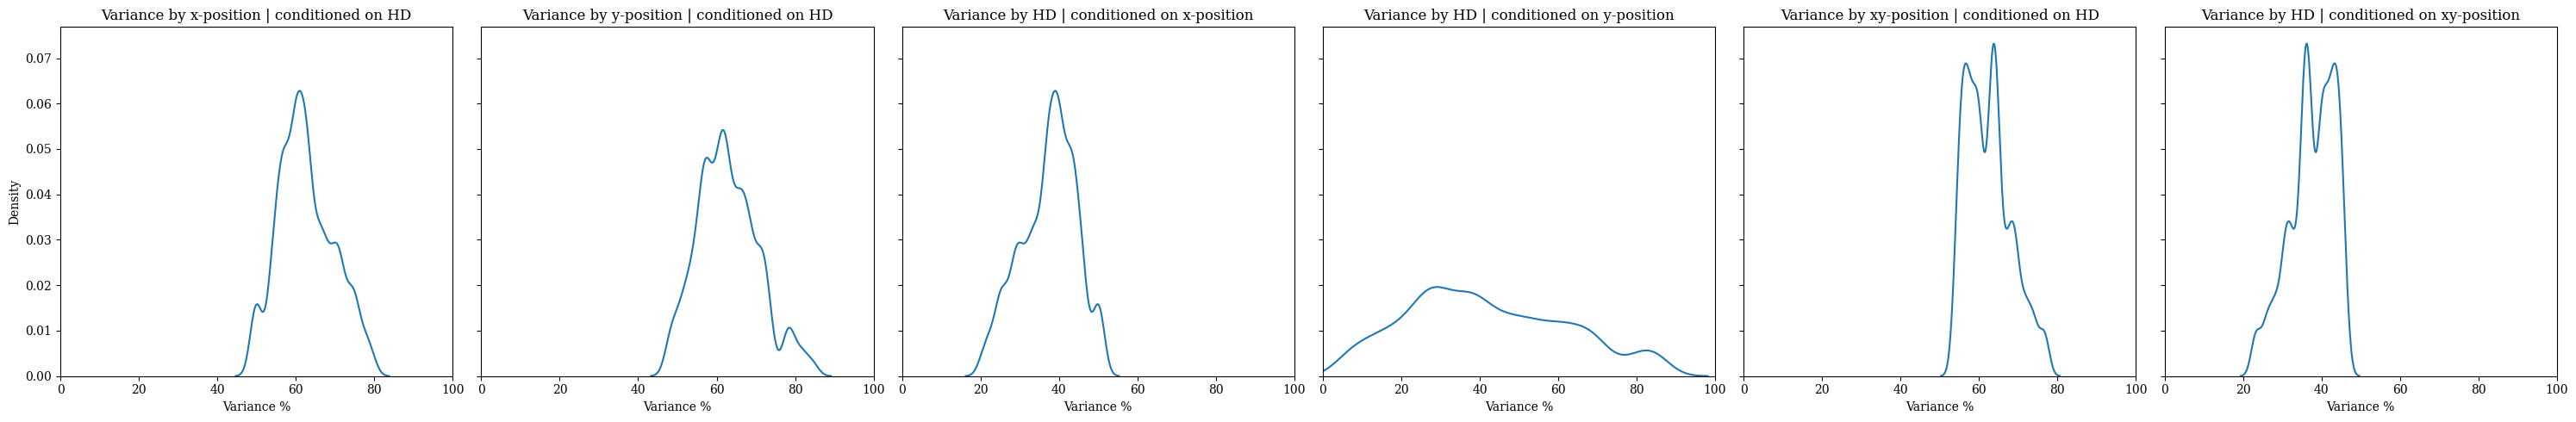

In [21]:
from scipy.stats import gaussian_kde
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

n_folds = 2
kf = KFold(n_splits=n_folds, shuffle=True, random_state=10)
n_neurons = smoothRateMaps.shape[2]

best_model_score = -np.inf
best_model_results = {}

for train_idx, test_idx in kf.split(range(n_neurons)):
    training_data = {
        'x_var': [],
        'y_var': [],
        'hd_x': [],
        'hd_y': [],
        'hd_xy': [],
        'xy_hd': [],
    }

    for i, idx in enumerate(train_idx):
        heatmap = hdRateMap[:, :, idx, :]
        x_marginal = np.sum(heatmap, axis=0) / hd_occ_x
        y_marginal = np.sum(heatmap, axis=1) / hd_occ_y

        x_var_conditioned_on_hd = [np.nanvar(x_marginal[:, rotation]) for rotation in range(n_rotations)]
        y_var_conditioned_on_hd = [np.nanvar(y_marginal[:, rotation]) for rotation in range(n_rotations)]

        hd_var_conditioned_on_x = [np.nanvar(x_marginal[bin_n, :]) for bin_n in range(n_bins)]
        hd_var_conditioned_on_y = [np.nanvar(y_marginal[bin_n, :]) for bin_n in range(n_bins)]

        hd_var_conditioned_on_xy = [np.nanvar(heatmap[x_bin, y_bin, :]) for x_bin in range(n_bins) for y_bin in range(n_bins)]
        xy_var_conditioned_on_hd = [np.nanvar(heatmap[:, :, rotation].flatten()) for rotation in range(n_rotations)]

        mean_hd_var_conditioned_on_x = np.nanmean(hd_var_conditioned_on_x)
        mean_hd_var_conditioned_on_y = np.nanmean(hd_var_conditioned_on_y)
        mean_x_var_conditioned_on_hd = np.nanmean(x_var_conditioned_on_hd)
        mean_y_var_conditioned_on_hd = np.nanmean(y_var_conditioned_on_hd)
        mean_hd_var_conditioned_on_xy = np.nanmean(hd_var_conditioned_on_xy)
        mean_xy_var_conditioned_on_hd = np.nanmean(xy_var_conditioned_on_hd)

        training_data['x_var'].append((mean_x_var_conditioned_on_hd / (mean_x_var_conditioned_on_hd + mean_hd_var_conditioned_on_x)) * 100)
        training_data['y_var'].append((mean_y_var_conditioned_on_hd / (mean_y_var_conditioned_on_hd + mean_hd_var_conditioned_on_y)) * 100)
        training_data['hd_x'].append((mean_hd_var_conditioned_on_x / (mean_x_var_conditioned_on_hd + mean_hd_var_conditioned_on_x)) * 100)
        training_data['hd_y'].append((mean_hd_var_conditioned_on_y / (mean_x_var_conditioned_on_hd + mean_hd_var_conditioned_on_y)) * 100)
        training_data['hd_xy'].append((mean_hd_var_conditioned_on_xy / (mean_hd_var_conditioned_on_xy + mean_xy_var_conditioned_on_hd)) * 100)
        training_data['xy_hd'].append((mean_xy_var_conditioned_on_hd / (mean_hd_var_conditioned_on_xy + mean_xy_var_conditioned_on_hd)) * 100)

    kde_models = {key: gaussian_kde(values) for key, values in training_data.items()}

    # split trials instead not neurons

    fold_likelihoods = []
    for i, idx in enumerate(test_idx):
        test_metrics = []

        heatmap = hdRateMap[:, :, idx, :]
        x_marginal = np.sum(heatmap, axis=0) / hd_occ_x
        y_marginal = np.sum(heatmap, axis=1) / hd_occ_y

        hd_var_conditioned_on_xy = [np.nanvar(heatmap[x_bin, y_bin, :]) for x_bin in range(n_bins) for y_bin in range(n_bins)]
        xy_var_conditioned_on_hd = [np.nanvar(heatmap[:, :, rotation].flatten()) for rotation in range(n_rotations)]
        x_var_conditioned_on_hd = [np.nanvar(x_marginal[:, rotation]) for rotation in range(n_rotations)]
        y_var_conditioned_on_hd = [np.nanvar(y_marginal[:, rotation]) for rotation in range(n_rotations)]
        hd_var_conditioned_on_x = [np.nanvar(x_marginal[bin_n, :]) for bin_n in range(n_bins)]
        hd_var_conditioned_on_y = [np.nanvar(y_marginal[bin_n, :]) for bin_n in range(n_bins)]

        mean_hd_var_conditioned_on_xy = np.nanmean(hd_var_conditioned_on_xy)
        mean_xy_var_conditioned_on_hd = np.nanmean(xy_var_conditioned_on_hd)
        mean_hd_var_conditioned_on_x = np.nanmean(hd_var_conditioned_on_x)
        mean_hd_var_conditioned_on_y = np.nanmean(hd_var_conditioned_on_y)
        mean_x_var_conditioned_on_hd = np.nanmean(x_var_conditioned_on_hd)
        mean_y_var_conditioned_on_hd = np.nanmean(y_var_conditioned_on_hd)

        test_metrics.append((mean_x_var_conditioned_on_hd / (mean_x_var_conditioned_on_hd + mean_hd_var_conditioned_on_x)) * 100)
        test_metrics.append((mean_y_var_conditioned_on_hd / (mean_y_var_conditioned_on_hd + mean_hd_var_conditioned_on_y)) * 100)
        test_metrics.append((mean_hd_var_conditioned_on_x / (mean_x_var_conditioned_on_hd + mean_hd_var_conditioned_on_x)) * 100)
        test_metrics.append((mean_hd_var_conditioned_on_y / (mean_x_var_conditioned_on_hd + mean_hd_var_conditioned_on_y)) * 100)
        test_metrics.append((mean_hd_var_conditioned_on_xy / (mean_hd_var_conditioned_on_xy + mean_xy_var_conditioned_on_hd)) * 100)
        test_metrics.append((mean_xy_var_conditioned_on_hd / (mean_hd_var_conditioned_on_xy + mean_xy_var_conditioned_on_hd)) * 100)

        # 'x_var', 'y_var', 'hd_x', 'hd_y', 'hd_xy', 'xy_hd'
        #likelihood = sum([kde_models[key].logpdf([value])[0] for key, value in zip(training_data.keys(), test_metrics)])
        likelihood = kde_models['hd_xy'].logpdf([test_metrics[-2]])[0] # I care mainly about this metric
        
        fold_likelihoods.append(likelihood)

    fold_mean_likelihood = np.mean(fold_likelihoods)

    if fold_mean_likelihood > best_model_score:
        best_model_score = fold_mean_likelihood
        best_model_results = {
            'x_var': training_data['x_var'],
            'y_var': training_data['y_var'],
            'hd_x': training_data['hd_x'],
            'hd_y': training_data['hd_y'],
            'hd_xy': training_data['hd_xy'],
            'xy_hd': training_data['xy_hd']
        }

fig, axes = plt.subplots(1, 6, figsize=(30, 5), sharey=True)

titles = [
    'Variance by x-position | conditioned on HD',
    'Variance by y-position | conditioned on HD',
    'Variance by HD | conditioned on x-position',
    'Variance by HD | conditioned on y-position',
    'Variance by xy-position | conditioned on HD',
    'Variance by HD | conditioned on xy-position',
]

best_data = [
    best_model_results['x_var'],
    best_model_results['y_var'],
    best_model_results['hd_x'],
    best_model_results['hd_y'],
    best_model_results['xy_hd'],
    best_model_results['hd_xy'],
]

pfeiffer_kde_data = {'layer': [], 'condition': [], 'x_values': [], 'density_values': []}

for col_idx, data in enumerate(best_data):
    ax = axes[col_idx]
    kde = sns.kdeplot(data, ax=ax, bw_adjust=0.5)
    ax.set_title(titles[col_idx])
    ax.set_ylabel('Density')
    ax.set_xlabel('Variance %')
    ax.set_xlim(0, 100)

    x_values = kde.get_lines()[0].get_xdata()
    density_values = kde.get_lines()[0].get_ydata()

    pfeiffer_kde_data['layer'].append('0')
    pfeiffer_kde_data['condition'].append(titles[col_idx])
    pfeiffer_kde_data['x_values'].append(x_values)
    pfeiffer_kde_data['density_values'].append(density_values)

plt.tight_layout()
#plt.savefig('best_variance_density_per_neuron_cv.png', dpi=300)

# Save best results to CSV
#pfeiffer_kde_df = pd.DataFrame(pfeiffer_kde_data)
#pfeiffer_kde_df.to_csv('results/pfeiffer/best_kde_distributions_cv.csv', index=False)


In [21]:

n_neurons = smoothRateMaps.shape[2]

x_var_results = np.zeros((n_neurons))
y_var_results = np.zeros((n_neurons))
hd_x_results = np.zeros((n_neurons))
hd_y_results = np.zeros((n_neurons))
hd_xy_results = np.zeros((n_neurons))
xy_hd_results = np.zeros((n_neurons))

for idx in tqdm(range(n_neurons)):
    heatmap = hdRateMap[:, :, idx, :]
    x_marginal = np.sum(heatmap, axis=0) / hd_occ_x
    y_marginal = np.sum(heatmap, axis=1) / hd_occ_y

    hd_var_conditioned_on_xy = []
    for x_bin in range(n_bins):
        for y_bin in range(n_bins):
            firing_rates_hd = heatmap[x_bin, y_bin, :]
            hd_variance = np.nanvar(firing_rates_hd)
            hd_var_conditioned_on_xy.append(hd_variance)

    xy_var_conditioned_on_hd = []
    for rotation in range(n_rotations):
        firing_rates_xy = heatmap[:, :, rotation].flatten()
        xy_variance = np.nanvar(firing_rates_xy)
        xy_var_conditioned_on_hd.append(xy_variance)

    mean_hd_var_conditioned_on_xy = np.nanmean(hd_var_conditioned_on_xy)
    mean_xy_var_conditioned_on_hd = np.nanmean(xy_var_conditioned_on_hd)

    hd_xy_results[idx] = (mean_hd_var_conditioned_on_xy / (mean_hd_var_conditioned_on_xy + mean_xy_var_conditioned_on_hd)) * 100
    xy_hd_results[idx] = (mean_xy_var_conditioned_on_hd / (mean_hd_var_conditioned_on_xy + mean_xy_var_conditioned_on_hd)) * 100

    x_var_conditioned_on_hd = []
    y_var_conditioned_on_hd = []
        
    # get the x and y conditioned variances
    for rotation in range(n_rotations):
        firing_rates_x = x_marginal[:, rotation]
        x_variance = np.nanvar(firing_rates_x)
        x_var_conditioned_on_hd.append(x_variance)
            
        firing_rates_y = y_marginal[:, rotation]
        y_variance = np.nanvar(firing_rates_y)
        y_var_conditioned_on_hd.append(y_variance)

    hd_var_conditioned_on_y = []
    hd_var_conditioned_on_x = []

    for bin_n in range(n_bins):
        firing_rates_hd_x = x_marginal[bin_n, :]
        hd_variance_x = np.nanvar(firing_rates_hd_x)
        hd_var_conditioned_on_x.append(hd_variance_x)
            
        firing_rates_hd_y = y_marginal[bin_n, :]
        hd_variance_y = np.nanvar(firing_rates_hd_y)
        hd_var_conditioned_on_y.append(hd_variance_y)
        
    # Average variance across all x-position bins
    mean_hd_var_conditioned_on_x = np.nanmean(hd_var_conditioned_on_x)
    mean_hd_var_conditioned_on_y = np.nanmean(hd_var_conditioned_on_y)
    mean_x_var_conditioned_on_hd = np.nanmean(x_var_conditioned_on_hd)
    mean_y_var_conditioned_on_hd = np.nanmean(y_var_conditioned_on_hd)
    x_var_results[idx] = (mean_x_var_conditioned_on_hd / (mean_x_var_conditioned_on_hd + mean_hd_var_conditioned_on_x)) * 100
    y_var_results[idx] = (mean_y_var_conditioned_on_hd / (mean_y_var_conditioned_on_hd + mean_hd_var_conditioned_on_y)) * 100
    hd_x_results[idx] = (mean_hd_var_conditioned_on_x / (mean_x_var_conditioned_on_hd + mean_hd_var_conditioned_on_x)) * 100
    hd_y_results[idx] = (mean_hd_var_conditioned_on_y / (mean_x_var_conditioned_on_hd + mean_hd_var_conditioned_on_y)) * 100

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

fig, axes = plt.subplots(1, 6, figsize=(30, 5), sharey=True)

titles = [
    'Variance by x-position | conditioned on HD',
    'Variance by y-position | conditioned on HD',
    'Variance by HD | conditioned on x-position',
    'Variance by HD | conditioned on y-position',
    'Variance by xy-position | conditioned on HD',
    'Variance by HD | conditioned on xy-position',
]

pfeiffer_kde_data = {'layer': [], 'condition': [], 'x_values': [], 'density_values': []}

for col_idx, data in enumerate([x_var_results, y_var_results, hd_x_results, hd_y_results, xy_hd_results, hd_xy_results]):
    ax = axes[col_idx]
    kde = sns.kdeplot(data, ax=ax, bw_adjust=0.5)
    #sns.kdeplot(data, ax=ax, fill=True, bw_adjust=0.5) 
    ax.set_title(titles[col_idx])
    ax.set_ylabel(f'Density')
    ax.set_xlabel('Variance %')
    ax.set_xlim(0, 100)  # Adjust the x-axis as necessary for your data range

    x_values = kde.get_lines()[0].get_xdata()
    density_values = kde.get_lines()[0].get_ydata()
    print(x_values[0])

    pfeiffer_kde_data['layer'].append(f'0')
    pfeiffer_kde_data['condition'].append(titles[col_idx])
    pfeiffer_kde_data['x_values'].append(x_values)
    pfeiffer_kde_data['density_values'].append(density_values)

plt.tight_layout()

# Save the figure
plt.savefig('variance_density_per_neuron.png', dpi=300)
#plt.close(fig)  # Close the figure to avoid displaying it in interactive environments


pfeiffer_kde_df = pd.DataFrame(pfeiffer_kde_data)

pfeiffer_kde_df.to_csv(f'results/pfeiffer/kde_distributions.csv', index=False)


  0%|                                                                                                   | 0/203 [00:00<?, ?it/s]/tmp/ipykernel_3027953/3380560004.py:52: RuntimeWarning: Degrees of freedom <= 0 for slice.
  hd_variance_x = np.nanvar(firing_rates_hd_x)
/tmp/ipykernel_3027953/3380560004.py:56: RuntimeWarning: Degrees of freedom <= 0 for slice.
  hd_variance_y = np.nanvar(firing_rates_hd_y)
100%|█████████████████████████████████████████████████████████████████████████████████████████| 203/203 [00:03<00:00, 62.47it/s]


In [96]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 6, figsize=(24, 5), sharey=True)

# Define titles for each column
titles = [
    'Variance by x-position | conditioned on HD',
    'Variance by y-position | conditioned on HD',
    'Variance by HD | conditioned on x-position',
    'Variance by HD | conditioned on y-position',
    'Variance by xy-position | conditioned on HD',
    'Variance by HD | conditioned on xy-position'
]

for col_idx, data in enumerate([x_var_results, y_var_results, hd_x_results, hd_y_results, xy_hd_results, hd_xy_results]):
    ax = axes[col_idx]
    ax.bar(range(len(data)), data)
    ax.set_title(titles[col_idx])
    if col_idx == 0:  # Label the rows with the layer name or index
        ax.set_ylabel(f'Variance %')
    ax.set_xlabel('Neuron index')
    ax.set_ylim(0, 200)  # Fixed y-limit for consistency across layers

plt.tight_layout()

figpath = f'figs/pfeiffer'

# Save the figure
plt.savefig(f'{figpath}/variance_explained_per_neuron.png', dpi=300)  # Adjust file name and dpi as needed
#plt.showfig()
plt.close(fig)  # Close the figure to avoid displaying it in interactive environments


45.332051345223896
43.7317826427539
16.826187811616006
-4.896219630279954
50.14859551132827
20.05690239973195


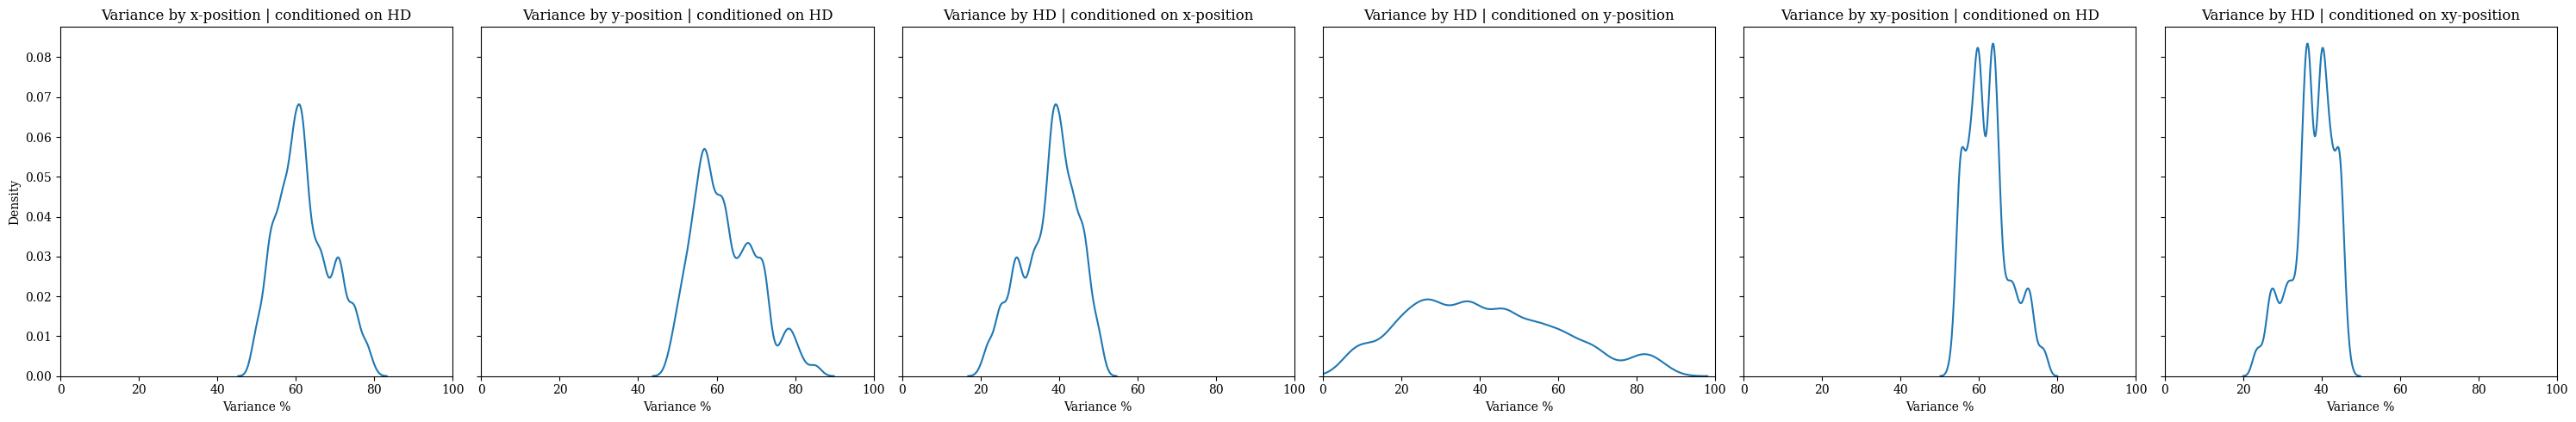

In [127]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

fig, axes = plt.subplots(1, 6, figsize=(30, 5), sharey=True)

titles = [
    'Variance by x-position | conditioned on HD',
    'Variance by y-position | conditioned on HD',
    'Variance by HD | conditioned on x-position',
    'Variance by HD | conditioned on y-position',
    'Variance by xy-position | conditioned on HD',
    'Variance by HD | conditioned on xy-position',
]

pfeiffer_kde_data = {'layer': [], 'condition': [], 'x_values': [], 'density_values': []}

for col_idx, data in enumerate([x_var_results, y_var_results, hd_x_results, hd_y_results, xy_hd_results, hd_xy_results]):
    ax = axes[col_idx]
    kde = sns.kdeplot(data, ax=ax, bw_adjust=0.5)
    #sns.kdeplot(data, ax=ax, fill=True, bw_adjust=0.5) 
    ax.set_title(titles[col_idx])
    ax.set_ylabel(f'Density')
    ax.set_xlabel('Variance %')
    ax.set_xlim(0, 100)  # Adjust the x-axis as necessary for your data range

    x_values = kde.get_lines()[0].get_xdata()
    density_values = kde.get_lines()[0].get_ydata()
    print(x_values[0])

    pfeiffer_kde_data['layer'].append(f'0')
    pfeiffer_kde_data['condition'].append(titles[col_idx])
    pfeiffer_kde_data['x_values'].append(x_values)
    pfeiffer_kde_data['density_values'].append(density_values)

plt.tight_layout()

# Save the figure
plt.savefig('variance_density_per_neuron.png', dpi=300)
#plt.close(fig)  # Close the figure to avoid displaying it in interactive environments


pfeiffer_kde_df = pd.DataFrame(pfeiffer_kde_data)

pfeiffer_kde_df.to_csv(f'results/pfeiffer/kde_distributions.csv', index=False)


### Distributional Overlap

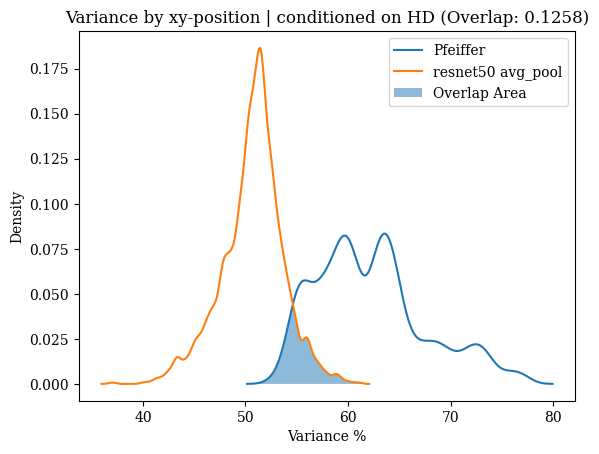

In [158]:
import numpy as np
import matplotlib.pyplot as plt

# Define the variable type and layer you're interested in
var_type = titles[4]
layer = layers[3]

# Extract the density values and x-values for both datasets
kde1_values = pfeiffer_kde_df[pfeiffer_kde_df['condition'] == var_type]['density_values'].iloc[0]
kde2_values = model_kde_df[(model_kde_df['layer'] == layer) & 
                           (model_kde_df['condition'] == var_type)]['density_values'].iloc[0]

pfeiffer_x = pfeiffer_kde_df[pfeiffer_kde_df['condition'] == var_type]['x_values'].iloc[0]
model_x = model_kde_df[(model_kde_df['layer'] == layer) & 
                       (model_kde_df['condition'] == var_type)]['x_values'].iloc[0]

# Find the overlapping x-range
x_min = max(min(pfeiffer_x), min(model_x))
x_max = min(max(pfeiffer_x), max(model_x))

# Create a common x-grid over the overlapping range
common_x = np.linspace(x_min, x_max, num=1000)

# Interpolate both density curves onto the common x-grid
interp_kde1 = np.interp(common_x, pfeiffer_x, kde1_values)
interp_kde2 = np.interp(common_x, model_x, kde2_values)

# Compute the minimum densities at each point in the common x-grid
min_densities = np.minimum(interp_kde1, interp_kde2)

# Calculate the overlap area using numerical integration
overlap = np.trapz(min_densities, common_x)

# Plot the density curves
plt.plot(pfeiffer_x, kde1_values, label='Pfeiffer')
plt.plot(model_x, kde2_values, label=f'{model_name} {layer}')

# Fill the area between the curves to represent the overlap
plt.fill_between(common_x, min_densities, alpha=0.5, label='Overlap Area')

# Add labels, title, and legend
plt.legend()
plt.title(f'{var_type} (Overlap: {overlap:.4f})')
plt.xlabel('Variance %')
plt.ylabel('Density')
plt.show()


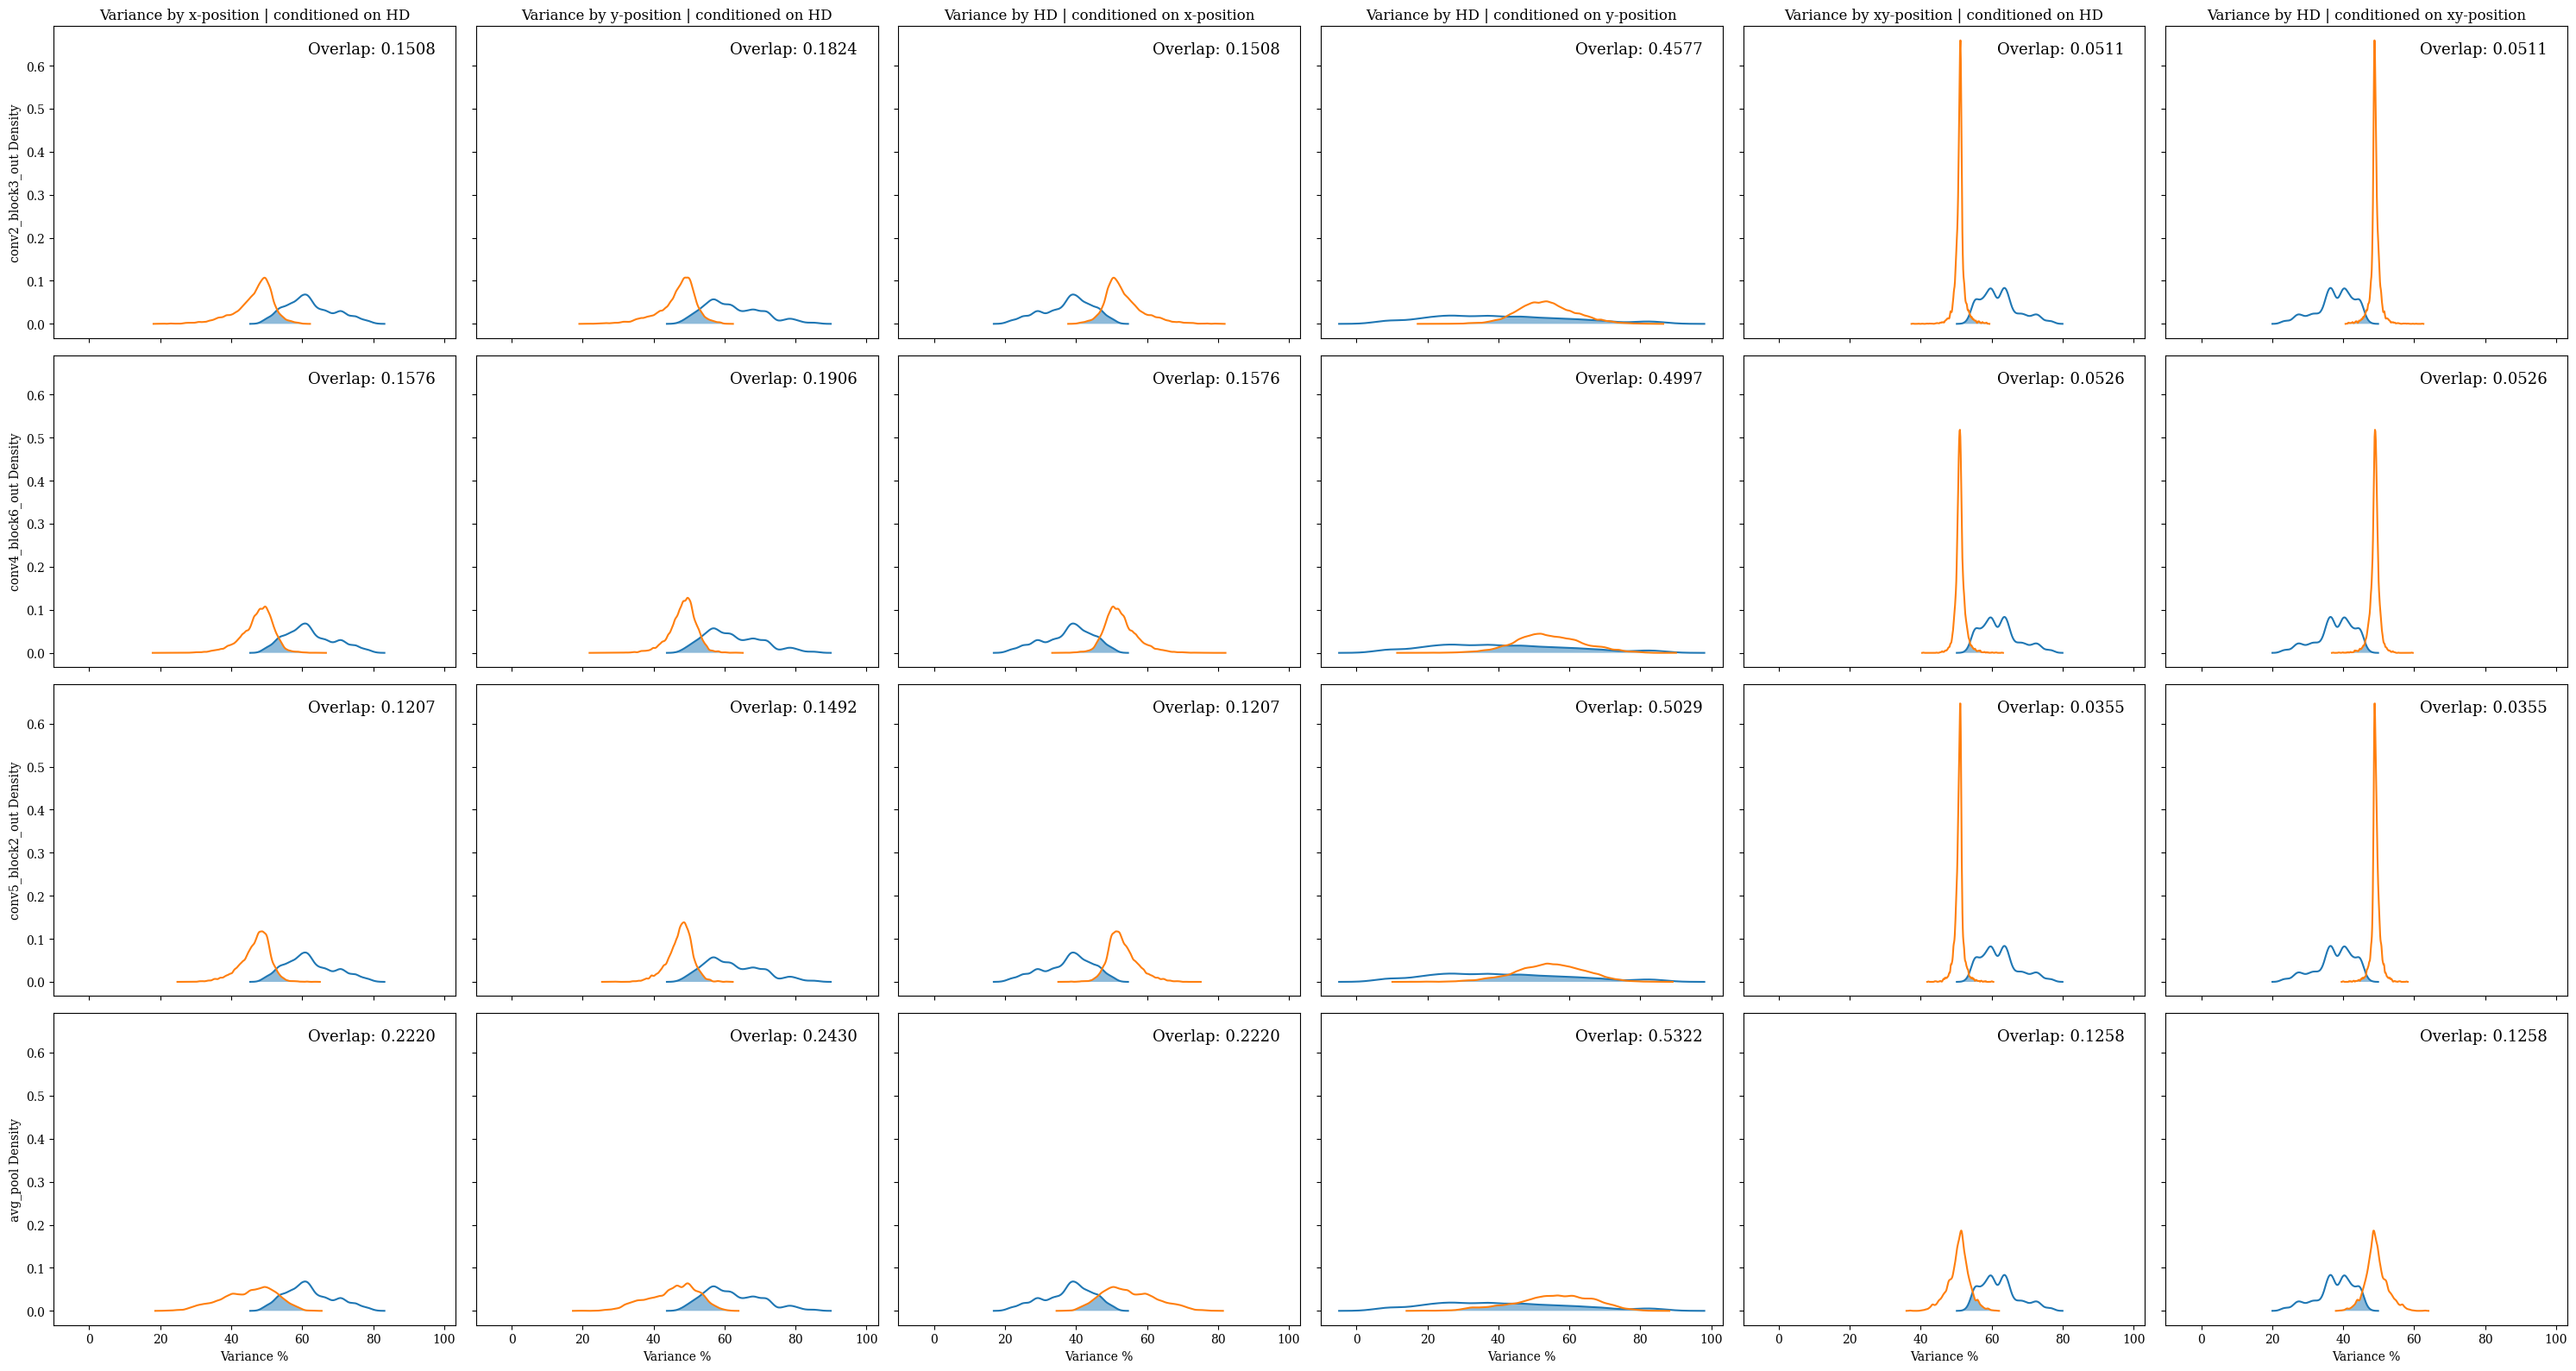

In [165]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming 'titles' is a list of var_types (variance types)
# Assuming 'layers' is a list of layer names from model_kde_df['layer'].unique()

# Get the list of unique variance types and layers
var_types = model_kde_df['condition'].unique()
layers = model_kde_df['layer'].unique()

n_var_types = len(var_types)
n_layers = len(layers)

# Create a figure with subplots arranged in n_layers rows and n_var_types columns
fig, axes = plt.subplots(n_layers, n_var_types, figsize=(5 * n_var_types, 4 * n_layers), sharex=True, sharey=True)

# Ensure axes is a 2D array for consistent indexing
if n_layers == 1:
    axes = np.array([axes])
if n_var_types == 1:
    axes = np.expand_dims(axes, axis=1)

# Loop over layers and var_types to create subplots
for i, layer in enumerate(layers):
    for j, var_type in enumerate(var_types):
        ax = axes[i, j]
        
        model_data_row = model_kde_df[(model_kde_df['layer'] == layer) & (model_kde_df['condition'] == var_type)]
        if model_data_row.empty:
            continue  # Skip if no data
        
        model_x = model_data_row['x_values'].iloc[0]
        model_y = model_data_row['density_values'].iloc[0]
        
        pfeiffer_data_row = pfeiffer_kde_df[pfeiffer_kde_df['condition'] == var_type]
        if pfeiffer_data_row.empty:
            continue  # Skip if no data
        
        pfeiffer_x = pfeiffer_data_row['x_values'].iloc[0]
        pfeiffer_y = pfeiffer_data_row['density_values'].iloc[0]
        
        x_min = max(min(pfeiffer_x), min(model_x))
        x_max = min(max(pfeiffer_x), max(model_x))
        common_x = np.linspace(x_min, x_max, num=1000)
        
        model_y_interp = np.interp(common_x, model_x, model_y)
        pfeiffer_y_interp = np.interp(common_x, pfeiffer_x, pfeiffer_y)
        
        # Plot the data
        ax.plot(pfeiffer_x, pfeiffer_y, label='Pfeiffer')
        ax.plot(model_x, model_y, label=f'Model {layer}')
        
        # Optionally fill the overlap area between the curves
        min_densities = np.minimum(pfeiffer_y_interp, model_y_interp)
        ax.fill_between(common_x, min_densities, alpha=0.5, label='Overlap Area')
        overlap = np.trapz(min_densities, common_x)

        ax.text(0.95, 0.95, f'Overlap: {overlap:.4f}',
            horizontalalignment='right',
            verticalalignment='top',
            transform=ax.transAxes,
            fontsize=13,
            bbox=dict(facecolor='white', alpha=0.5, edgecolor='none'))

        # Set titles and labels
        if i == 0:
            ax.set_title(var_type)
        if j == 0:
            ax.set_ylabel(f'{layer} Density')
        if i == n_layers - 1:
            ax.set_xlabel('Variance %')
        
        # Optionally add legends (e.g., only to the first subplot)
        if i == 0 and j == len(var_types):
            ax.legend()

# Adjust layout for a cleaner look
plt.tight_layout()
plt.savefig(f'{model_name}_pfeiffer_density_comparison.png', dpi=300)
plt.show()



## Mixture of Models

In [181]:

# testing 
n_neurons = 200
max_visits = 20

rotation_noise_level = 0.02
visit_noise_level = 0.02

n_hd_rates = np.zeros((n_neurons, n_bins, n_bins, n_rotations))
n_smoothed_maps = np.zeros((n_neurons, n_bins, n_bins))

for n in range(n_neurons):
    base_matrix = np.random.rand(n_bins, n_bins)
    
    heatmap = np.zeros((n_bins, n_bins, n_rotations, max_visits))
    
    for i in range(n_bins):
        for j in range(n_bins):

            # randomly make some bins low visit/nan
            if np.random.randint(low=0, high=11) < 3:
                n_smoothed_maps[n, i, j] = np.nan
                n_hd_rates[n, i, j, :] = np.nan
                continue
            
            rotation_noise = np.random.normal(0, rotation_noise_level, size=(n_rotations,))
            
            for r in range(n_rotations):
                num_visits = np.random.randint(1, max_visits + 1)
                
                visit_rates = base_matrix[i, j] + rotation_noise[r]
                visit_rates += np.random.normal(0, visit_noise_level, size=num_visits)
                
                heatmap[i, j, r, :num_visits] = visit_rates
                heatmap[i, j, r, num_visits:] = np.nan
                
                n_hd_rates[n, i, j, r] = np.nanmean(heatmap[i, j, r])

            n_smoothed_maps[n, i, j] = np.nanmean(heatmap[i, j])
    
    

In [175]:
n_neurons = 200

100%|██████████████████████████████████████████████████████████████████████████████████████| 203/203 [00:00<00:00, 10376.12it/s]


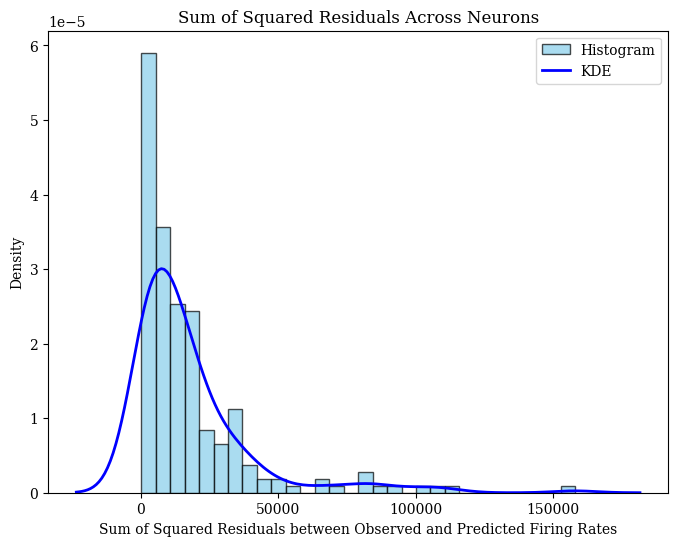

In [298]:


import numpy as np
from sklearn.metrics import r2_score
from scipy.stats import linregress
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

envLen = 200
#n_bins = 17
#n_rotations = 16
binWidth = envLen / n_bins

seed = 777

# Load data
#smoothRateMaps = np.load(f'/home/mag/Space/results/pfeiffer/smoothRateMaps_seed_{seed}.npy')  # n_bins x n_bins x n_neurons
#rateMaps = np.load(f'/home/mag/Space/results/pfeiffer/rateMaps_seed_{seed}.npy')  # n_bins x n_bins x n_neurons
#hdRateMap = np.load(f'/home/mag/Space/results/pfeiffer/hdRateMap_seed_{seed}.npy')  # n_bins x n_bins x n_neurons x n_rotations

#n_neurons = smoothRateMaps.shape[2]

r2_results = np.zeros(n_neurons)

for neuron in tqdm(range(n_neurons)):
    #observed_rates = n_hd_rates[neuron]
    observed_rates = hdRateMap[:, :, neuron, :]  # Shape: (n_bins, n_bins, n_rotations)

    #f1_xy = n_smoothed_maps[neuron]
    f1_xy = smoothRateMaps[:, :, neuron]  # Shape: (n_bins, n_bins)

    f1_xy_expanded = np.repeat(f1_xy[:, :, np.newaxis], n_rotations, axis=2)  # Shape: (n_bins, n_bins, n_rotations)

    residuals = observed_rates - f1_xy_expanded  # Shape: (n_bins, n_bins, n_rotations)

    residuals_flat = residuals.flatten()
    valid_mask = ~np.isnan(residuals_flat)

    observed_flat = observed_rates.flatten()
    predicted_flat = f1_xy_expanded.flatten()
    valid_mask_r2 = ~np.isnan(observed_flat) & ~np.isnan(predicted_flat)
    if np.any(valid_mask_r2):
        #r_squared = r2_score(observed_flat[valid_mask_r2], predicted_flat[valid_mask_r2])
        r_squared = np.nansum((residuals)**2)
        r2_results[neuron] = r_squared
    else:
        r2_results[neuron] = np.nan

# Plot R² values with KDE over histogram
plt.figure(figsize=(8, 6))
plt.hist(r2_results[~np.isnan(r2_results)], bins=30, color='skyblue', edgecolor='k', alpha=0.7, density=True, label='Histogram')
sns.kdeplot(r2_results[~np.isnan(r2_results)], color='blue', label='KDE', linewidth=2)
#plt.xlim(-10, 100000)
plt.xlabel('Sum of Squared Residuals between Observed and Predicted Firing Rates')
plt.ylabel('Density')
plt.title('Sum of Squared Residuals Across Neurons')
plt.legend()
plt.show()



In [291]:
hdRateMap[:, :, 0, :].shape

(17, 17, 16)

In [190]:
valid_mask_r2

array([ True,  True,  True, ...,  True,  True,  True])

25


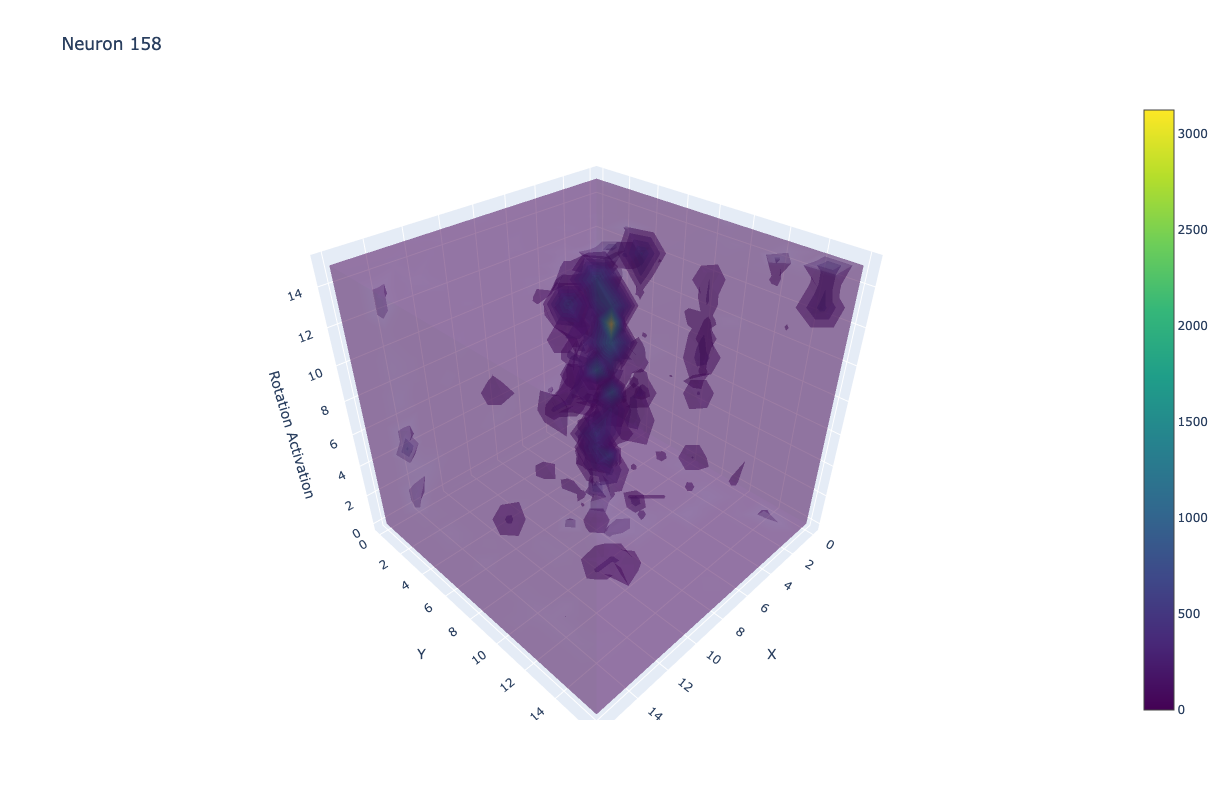

In [135]:
import plotly.graph_objects as go
%matplotlib widget

#envLen = 200
i += 1

print(len(significant_neurons))
idx = significant_neurons[i]

data = hdRateMap[:, :, idx, :]

#n_bins = binCount
#n_rotations = hdBinCount

x, y, z = np.meshgrid(np.arange(n_bins), np.arange(n_bins), np.arange(n_rotations))

x_flat = x.flatten()
y_flat = y.flatten()
z_flat = z.flatten()
data_flat = data.flatten()

fig = go.Figure(data=go.Volume(
    x=x_flat,
    y=y_flat,
    z=z_flat,
    value=data_flat,
    opacity=0.3,
    isomin=0,#np.min(data),   
    isomax=np.max(data),  
    surface_count=20,
    colorscale='Viridis'
))

fig.update_layout(
    title=f"Neuron {idx}",
    scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Rotation Activation',
        xaxis=dict(nticks=10),
        yaxis=dict(nticks=10),
        zaxis=dict(nticks=10),
    ),
    width=800,
    height=800
)

fig.show()



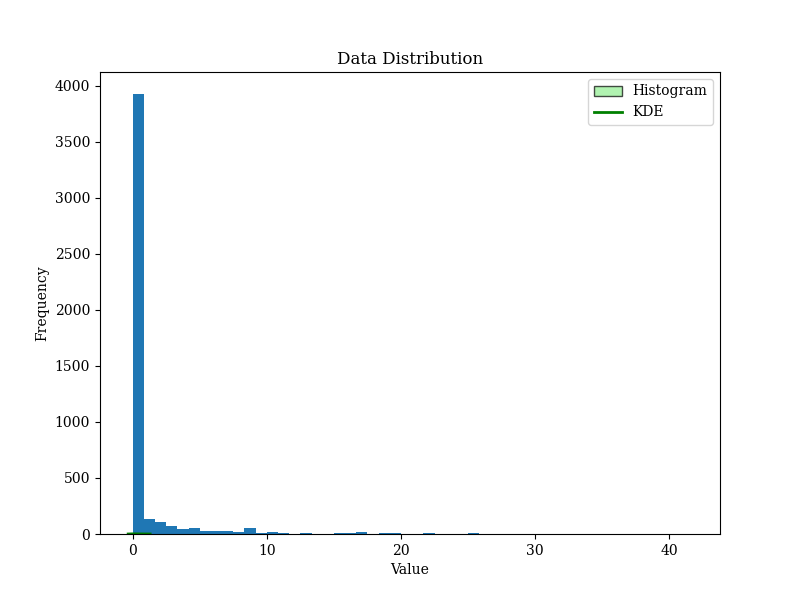

In [145]:
import matplotlib.pyplot as plt

plt.hist(observed_flat, bins=50)
plt.title("Data Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()


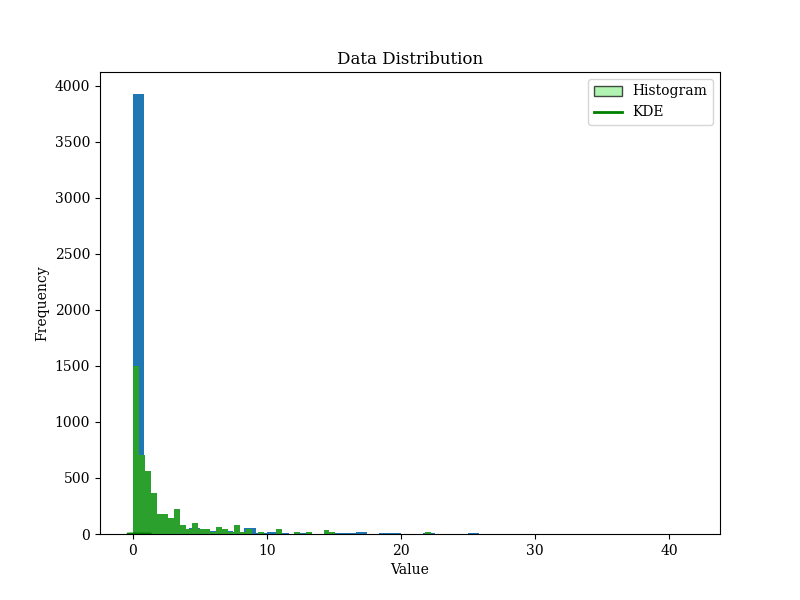

In [147]:
import matplotlib.pyplot as plt

plt.hist(predicted_flat, bins=50)
plt.title("Data Distribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()


In [74]:
significant_neurons

array([  2,   3,   4,   6,   7,   9,  10,  20,  28,  30,  35,  43,  44,
        49,  51,  54,  57,  59,  60,  75,  76,  93,  97, 103, 106, 108,
       109, 112, 118, 121, 128, 132, 135, 136, 142, 147, 151, 157, 158,
       159, 160, 168, 172, 173, 179, 184, 186, 190, 202])

In [214]:
import numpy as np
from sklearn.metrics import r2_score
from scipy.optimize import minimize
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

envLen = 200
n_bins = 17
n_rotations = 16
binWidth = envLen/n_bins

smoothRateMaps = np.load(f'/home/mag/Space/results/pfeiffer/smoothRateMaps.npy') # smoothed xy map: n_bins, n_bins, n_neurons
hdRateMap = np.load(f'/home/mag/Space/results/pfeiffer/hdRateMap.npy') # firing rate per hd: n_bins, n_bins, n_rotations, n_neurons
hdOccupancyMap = np.load(f'/home/mag/Space/results/pfeiffer/hdOccupancyMap.npy') # visit counts: n_bins, n_bins, n_rotations

# Func_tion for head direction
def f_const(bins):
    return np.ones(bins.shape)

# 2D Gaussian function
def gaussian_2d(x, y, mu_x, mu_y, sigma_x, sigma_y, rho, A):
    # Compute covariance matrix
    cov_matrix = np.array([
        [sigma_x**2, 0],
        [0, sigma_y**2]
    ])
    cov_matrix += np.eye(2) * 1e-6
    # Check for singular covariance matrix
    try:
        inv_cov = np.linalg.inv(cov_matrix)
        det_cov = np.linalg.det(cov_matrix)
        if det_cov <= 0:  # Ensure determinant is positive
            raise ValueError("Covariance matrix is singular or non-positive definite.")
    except np.linalg.LinAlgError:
        inv_cov = np.eye(2)  # Default to identity matrix
        det_cov = 1.0

    x_grid, y_grid = np.meshgrid(x, y, indexing='ij') 
    diff = np.stack([x_grid - mu_x, y_grid - mu_y], axis=-1)
    
    exp_term = np.einsum('...i,ij,...j->...', diff, inv_cov, diff)
    exp_term = np.clip(exp_term, -100, 100)  # Clip to prevent overflow
    gaussian = A * np.exp(-0.5 * exp_term) / (2 * np.pi * np.sqrt(det_cov))
    #gaussian = A * np.exp(-0.5 * exp_term)
    #return gaussian
    return np.nan_to_num(gaussian)  # Replace NaNs with 0

# Model for place cell firing rates
def place_cell_model(x, y, hd, mu_x, mu_y, sigma_x, sigma_y, rho, A):
    f_xy = gaussian_2d(x, y, mu_x, mu_y, sigma_x, sigma_y, rho, A)
    f_hd_vals = f_const(hd)
    return f_xy[..., None] * f_hd_vals

def model_error(params, x, y, hd, firing_rate):
    mu_x, mu_y, sigma_x, sigma_y, rho, A = params
    predicted_rate = place_cell_model(x, y, hd, mu_x, mu_y, sigma_x, sigma_y, rho, A)
    error = np.nanmean((firing_rate - predicted_rate)**2)
    return error if np.isfinite(error) else np.inf


n_bins = 17
n_rotations = 16
n_neurons = hdRateMap.shape[2]

x = np.arange(0, n_bins)
y = np.arange(0, n_bins)
theta = np.arange(0, n_rotations)

# Initialize results array
r2_results = np.zeros(n_neurons)
predicted_ratemaps = np.zeros((n_neurons, n_bins, n_bins, n_rotations))
fitted_params = np.zeros((n_neurons, 6))

# Iterate over neurons
for neuron in tqdm(range(n_neurons)):
    # Compute firing rate heatmap
    heatmap = hdRateMap[:, :, neuron, :] / (hdOccupancyMap + 1e-8)  # Avoid division by zero
    heatmap = np.nan_to_num(heatmap)  # Replace NaNs with 0

    # Initial guesses for optimization
    initial_params = [np.mean(x), np.mean(y), np.std(x), np.std(y), 0, np.max(heatmap)]  # rho starts at 0
    
    # Optimize parameters
    try:
        bounds = [
            (0, n_bins),      # mu_x: within the range of x
            (0, n_bins),      # mu_y: within the range of y
            (1e-3, n_bins),   # sigma_x: strictly positive
            (1e-3, n_bins),   # sigma_y: strictly positive
            (-0.5, 0.5),     # rho: within [-1, 1] but avoid exactly ±1,
            (0, None)
        ]

        result = minimize(
            model_error,
            initial_params,
            args=(x, y, theta, heatmap),
            bounds=bounds
        )
    except ValueError as e:
        print(f"Neuron {neuron}: Optimization failed with error {e}")
        r2_results[neuron] = np.nan
        continue

    # Extract optimized parameters
    mu_x_opt, mu_y_opt, sigma_x_opt, sigma_y_opt, rho_opt, A_opt = result.x
    fitted_params[neuron] = result.x

    # Compute optimized firing rate and R²
    optimized_rate = place_cell_model(x, y, theta, mu_x_opt, mu_y_opt, sigma_x_opt, sigma_y_opt, rho_opt, A_opt)
    predicted_ratemaps[neuron] = optimized_rate
    
    if not np.any(np.isnan(optimized_rate)):
        r_squared = r2_score(heatmap.flatten(), optimized_rate.flatten())
        r2_results[neuron] = r_squared if np.isfinite(r_squared) else np.nan
    else:
        r2_results[neuron] = np.nan



100%|█████████████████████████████████████████████████████████████████████████████████████████| 203/203 [00:38<00:00,  5.31it/s]


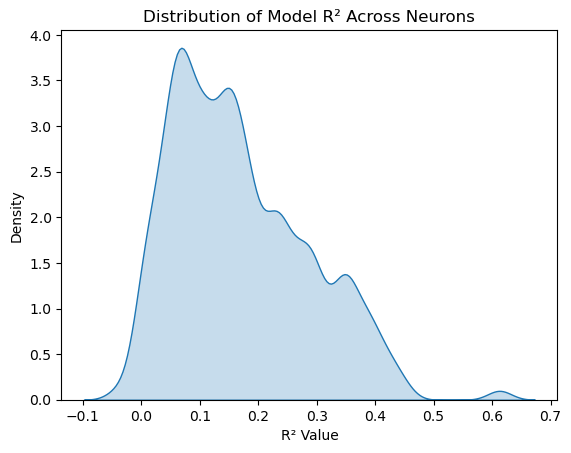

In [215]:
# Plot results
results = np.nan_to_num(r2_results, nan=0)  # Replace Na
sns.kdeplot(r2_results, fill=True, bw_adjust=0.5)  # Adjust bandwidth with `bw_adjust` for smoothing
plt.title("Distribution of Model R² Across Neurons")
plt.xlabel("R² Value")
plt.ylabel("Density")
plt.show()


In [229]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns  # Import seaborn for the KDE plot

# Assuming n_neurons, n_bins, hdRateMap, hdOccupancyMap, predicted_ratemaps, fitted_params, and r2_results are already defined

bin_size = 200 // n_bins
pdf = PdfPages('pfeiffer_model_fits.pdf')

# --- Add R² Distribution Plot on the First Page ---

# Replace NaNs in r2_results with zeros
r2_results_clean = np.nan_to_num(r2_results, nan=0)

# Create figure for R² distribution
fig_r2 = plt.figure(figsize=(8, 6))
sns.kdeplot(r2_results_clean, fill=True, bw_adjust=0.5)
plt.title("Distribution of Model R² Across Neurons")
plt.xlabel("R² Value")
plt.ylabel("Density")
plt.tight_layout()

# Save the R² distribution plot to the PDF
pdf.savefig(fig_r2)
plt.close(fig_r2)

# --- Loop Over Neurons and Generate Dual Plots ---

for neuron_idx in tqdm(range(n_neurons)):
    # First heatmap: Observed tuning curve
    heatmap1 = np.sum(hdRateMap[:, :, neuron_idx, :] / (hdOccupancyMap + 1e-8), axis=2)
    
    # Second heatmap: Predicted tuning curve
    heatmap2 = np.sum(predicted_ratemaps[neuron_idx, :, :, :], axis=2)
    
    params = fitted_params[neuron_idx]
    
    # Create the figure and subplots
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Plot the first heatmap
    im1 = axes[0].imshow(heatmap1, extent=[0, n_bins * bin_size, 0, n_bins * bin_size],
                         origin='lower', aspect='auto', cmap='hot')
    axes[0].set_title('Observed 2D Position Tuning Curve')
    axes[0].set_xlabel('X Position ')
    axes[0].set_ylabel('Y Position ')
    cbar1 = fig.colorbar(im1, ax=axes[0])
    cbar1.set_label('Firing Rate')
    
    # Plot the second heatmap
    im2 = axes[1].imshow(heatmap2, extent=[0, n_bins * bin_size, 0, n_bins * bin_size],
                         origin='lower', aspect='auto', cmap='hot')
    axes[1].set_title('Predicted 2D Position Tuning Curve')
    axes[1].set_xlabel('X Position ')
    axes[1].set_ylabel('Y Position ')
    cbar2 = fig.colorbar(im2, ax=axes[1])
    cbar2.set_label('Firing Rate')
    
    fig.suptitle(f'Neuron Index: {neuron_idx}', fontsize=16)#, y=0.9)
    
    # Adjust layout and save the figure to the PDF
    plt.tight_layout()
    pdf.savefig(fig)
    plt.close(fig)

# Close the PDF file
pdf.close()


100%|█████████████████████████████████████████████████████████████████████████████████████████| 203/203 [01:36<00:00,  2.10it/s]


In [ ]:
r2_results_clean = np.nan_to_num(r2_per_layer[l])
    
# Create figure for R² distribution
fig_r2 = plt.figure(figsize=(8, 6))
sns.kdeplot(r2_results_clean, fill=True, bw_adjust=0.5)
plt.title("Distribution of Model R² Across Neurons")
plt.xlabel("R² Value")
plt.ylabel("Density")
plt.tight_layout()
    
pdf.savefig(fig_r2)
plt.close(fig_r2)